# 01 — Data Audit and Feasibility Assessment

**Project:** *Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples*

**Phase 1 of the analysis plan.** This notebook audits the input data and evaluates the cross-survey feasibility gate defined in the proposal (Section 3). It does **not** fit any model: no Bayesian inference, Gaussian-process fitting or RAR parameter estimation happens here.

| | |
|---|---|
| Inputs | SPARC galaxy table (`SPARC_Lelli2016c.mrt`), SPARC mass-model files (`Rotmod_LTG/*_rotmod.dat`), unified HI corpus v7 (JSON, flat CSV, README) |
| Outputs | Audit tables in `03_Processed_Data/`, report in `05_Results/Tables/Dataset_Feasibility_Report.md`, diagnostic figures in `05_Results/Figures/` |
| Original data | Read-only. The notebook never writes into `01_Datasets/`. |

**How to read the outputs.** Every column in the exported tables is labelled in `data_dictionary.csv` as either a *confirmed dataset field* (copied from an input file) or a *derived quantity* (computed here). Derived quantities that need a stellar mass-to-light ratio use fixed fiducial values and exist **only** for auditing (unit checks, population descriptors). They are not inputs to inference.

## 1. Research Overview

Proposal elements this notebook implements (unchanged from the final proposal):

* **SPARC quality cuts, fixed before modelling:** quality flag `Q ≤ 2` and inclination `i ≥ 30°`.
* **Extension candidates:** THINGS and LITTLE THINGS galaxies from the unified corpus. Galaxies also in SPARC are identified by name (and position where available) and are **not** counted as independent data.
* **WALLABY:** excluded from the main analysis unless independent stellar and gas mass models with uncertainties can be assembled.
* **Feasibility gate:** the proposal expects roughly 20–40 independent non-SPARC galaxies with usable decompositions. **If fewer than ~15 pass, the paper becomes SPARC-only.** This notebook uses 15 as the numerical threshold.

Feasibility categories applied to each THINGS / LITTLE THINGS galaxy:

* **A — Ready:** radii, rotation velocities, velocity uncertainties, gas and stellar-disk contributions (and bulge where applicable), distance, inclination, and mass-to-light information are all present in the available files.
* **B — Requires external baryonic data:** a rotation curve is present, but baryonic components or other required inputs must be retrieved from the original survey papers.
* **C — Not usable with available data:** no rotation curve (or no radii/velocities) in the available files.

Category B is never counted as ready, and no baryonic decomposition is approximated or filled in.

## 2. Environment Setup

Installs only what is missing (Colab normally already has all three packages), then defines **all paths and settings in one configuration cell**.

In [1]:
import sys, importlib.util, subprocess

IN_COLAB = "google.colab" in sys.modules

# Only third-party packages this notebook needs. Everything else is standard library.
REQUIRED_PACKAGES = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib"}
missing = [pip for mod, pip in REQUIRED_PACKAGES.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All required packages already installed.")

import os, re, json, hashlib, logging, platform, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

RUN_TIMESTAMP = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
print(f"Run started (UTC): {RUN_TIMESTAMP}")
print(f"Running in Colab: {IN_COLAB}")
print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")

All required packages already installed.
Run started (UTC): 2026-10-22T08:34:18Z
Running in Colab: True
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0


In [2]:
# =====================================================================
# CONFIGURATION — the single place where paths and settings are defined
# =====================================================================

# --- Google Drive and project root ---------------------------------------
DRIVE_MOUNT_POINT = Path("/content/drive")
DRIVE_ROOT        = DRIVE_MOUNT_POINT / "MyDrive"
# RAR_PROJECT_ROOT lets the notebook run outside Colab (e.g. local testing).
PROJECT_ROOT = Path(os.environ.get("RAR_PROJECT_ROOT", str(DRIVE_ROOT / "RAR_Universality_Research")))

# --- Inputs (read-only) ---------------------------------------------------
DATASETS_DIR   = PROJECT_ROOT / "01_Datasets"
SPARC_DIR      = DATASETS_DIR / "SPARC"
SPARC_MRT      = SPARC_DIR / "SPARC_Lelli2016c.mrt"
ROTMOD_DIR     = SPARC_DIR / "Rotmod_LTG"          # already-extracted per-galaxy files
ROTMOD_PATTERN = "*_rotmod.dat"
UNIFIED_DIR    = DATASETS_DIR / "UNIFIED_HI"
UNIFIED_README = UNIFIED_DIR / "READMEv7.md"
UNIFIED_JSON   = UNIFIED_DIR / "rotation_curve_corpus_v7.json"
UNIFIED_CSV    = UNIFIED_DIR / "rotation_curve_corpus_v7.1_flat.csv"

# --- Outputs ---------------------------------------------------------------
PROCESSED_DIR      = PROJECT_ROOT / "03_Processed_Data"
RESULTS_TABLES_DIR = PROJECT_ROOT / "05_Results" / "Tables"
FIGURES_DIR        = PROJECT_ROOT / "05_Results" / "Figures"
LOG_DIR            = PROCESSED_DIR / "logs"
REPORT_PATH        = RESULTS_TABLES_DIR / "Dataset_Feasibility_Report.md"

# --- Settings fixed by the final proposal ----------------------------------
Q_MAX                = 2      # keep SPARC galaxies with quality flag Q <= 2
INC_MIN_DEG          = 30.0   # keep SPARC galaxies with inclination >= 30 deg
GATE_MIN_INDEPENDENT = 15     # "If fewer than ~15 pass, the paper becomes SPARC-only"
EXTENSION_SURVEYS    = ("THINGS", "LITTLE_THINGS")
EXCLUDED_SURVEYS     = ("WALLABY",)

# --- Audit settings chosen here (documented, not from the proposal) ----------
POS_TOL_STRONG_ARCSEC = 30.0    # separation treated as a positional match
POS_TOL_REVIEW_ARCSEC = 120.0   # separations up to this are flagged for manual review
DIST_HEADER_TOL_MPC   = 0.011   # rotmod header distance vs MRT distance (rounding tolerance)
G_PLAUSIBLE_MS2       = (1e-14, 1e-7)  # very wide sanity window for accelerations (m s^-2)

# --- Constants used only for audit-level derived quantities -----------------
KPC_IN_M = 3.0856775814913673e19   # 1 kpc in metres
KMS_IN_MS = 1.0e3                  # 1 km/s in m/s
FIDUCIAL_UPSILON_DISK  = 0.5       # fiducial [3.6] M/L, disk (audit/unit check only)
FIDUCIAL_UPSILON_BULGE = 0.7       # fiducial [3.6] M/L, bulge (audit/unit check only)
HELIUM_FACTOR          = 1.33      # M_gas = 1.33 M_HI convention (audit descriptor only)

INPUT_COMPONENTS = {
    "SPARC galaxy table (MRT)":       ("file", SPARC_MRT),
    "SPARC rotation-curve files":     ("dir",  ROTMOD_DIR),
    "Unified corpus README":          ("file", UNIFIED_README),
    "Unified corpus JSON":            ("file", UNIFIED_JSON),
    "Unified corpus flat CSV":        ("file", UNIFIED_CSV),
}
print("Project root:", PROJECT_ROOT)

Project root: /content/drive/MyDrive/RAR_Universality_Research


## 3. Google Drive Mounting

In Colab this asks for permission to access your Drive. Outside Colab it is skipped and `RAR_PROJECT_ROOT` must point to a local copy of the project folder.

In [3]:
if IN_COLAB:
    from google.colab import drive
    drive.mount(str(DRIVE_MOUNT_POINT))
    if not DRIVE_ROOT.exists():
        raise FileNotFoundError(
            f"Google Drive mounted but '{DRIVE_ROOT}' was not found. "
            "Re-run this cell and complete the authorisation prompt.")
    print("Google Drive mounted at", DRIVE_MOUNT_POINT)
else:
    print("Not running in Colab: skipping Drive mount.")
    print("Using PROJECT_ROOT =", PROJECT_ROOT)

Mounted at /content/drive
Google Drive mounted at /content/drive


## 4. Dataset Path Verification

Checks the project folder and all five dataset components, creates output folders, sets up logging, and records file sizes, formats and SHA-256 checksums.

In [4]:
def _list_dir_for_error(p: Path, limit=30):
    # Shows what *does* exist so a path error is easy to fix.
    if p.exists() and p.is_dir():
        items = sorted(x.name + ("/" if x.is_dir() else "") for x in p.iterdir())
        return ", ".join(items[:limit]) + (" ..." if len(items) > limit else "")
    return "(directory does not exist)"

if not PROJECT_ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_ROOT}\n"
        f"Contents of {PROJECT_ROOT.parent}: {_list_dir_for_error(PROJECT_ROOT.parent)}\n"
        "Check the folder name and capitalisation (expected 'RAR_Universality_Research' in MyDrive).")

problems = []
for label, (kind, path) in INPUT_COMPONENTS.items():
    if kind == "file" and not path.is_file():
        problems.append(f"- {label}: missing file {path}\n    parent contains: {_list_dir_for_error(path.parent)}")
    if kind == "dir" and not path.is_dir():
        problems.append(f"- {label}: missing folder {path}\n    parent contains: {_list_dir_for_error(path.parent)}")
if problems:
    raise FileNotFoundError("Required dataset components are missing:\n" + "\n".join(problems))

rotmod_files = sorted(ROTMOD_DIR.glob(ROTMOD_PATTERN))
if not rotmod_files:
    raise FileNotFoundError(
        f"No files matching '{ROTMOD_PATTERN}' in {ROTMOD_DIR}. "
        f"Folder contains: {_list_dir_for_error(ROTMOD_DIR)}")
other_in_rotmod = sorted(p.name for p in ROTMOD_DIR.iterdir() if p.is_file() and p not in set(rotmod_files))
print(f"All 5 dataset components found. Rotation-curve files: {len(rotmod_files)}")
if other_in_rotmod:
    print("Note: other files in Rotmod_LTG (ignored):", other_in_rotmod[:20])

All 5 dataset components found. Rotation-curve files: 175


In [5]:
# Create output folders and guard against writing into the raw-data folder.
for d in (PROCESSED_DIR, RESULTS_TABLES_DIR, FIGURES_DIR, LOG_DIR):
    if DATASETS_DIR.resolve() in d.resolve().parents or d.resolve() == DATASETS_DIR.resolve():
        raise RuntimeError(f"Output directory {d} is inside the raw dataset folder; refusing to write there.")
    d.mkdir(parents=True, exist_ok=True)

# Logging to file and notebook output.
LOG_PATH = LOG_DIR / "01_data_audit.log"
logger = logging.getLogger("rar_audit")
logger.setLevel(logging.INFO)
logger.handlers.clear()
_fh = logging.FileHandler(LOG_PATH, mode="w", encoding="utf-8")
_fh.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
_sh = logging.StreamHandler(sys.stdout)
_sh.setFormatter(logging.Formatter("%(levelname)s: %(message)s"))
logger.addHandler(_fh); logger.addHandler(_sh)
logger.info(f"Audit run {RUN_TIMESTAMP}; project root {PROJECT_ROOT}")

# Integrity-check registry: every check is recorded; critical failures stop the notebook at the end.
CHECKS = []
def record_check(section, name, passed, detail="", severity="critical"):
    status = "PASS" if passed else ("FAIL" if severity == "critical" else "WARN")
    CHECKS.append({"section": section, "check": name, "status": status,
                   "severity": severity, "detail": str(detail)})
    (logger.info if passed else (logger.error if severity == "critical" else logger.warning))(
        f"[{status}] {section} | {name} | {detail}")
    return bool(passed)

print("Output folders ready:")
for d in (PROCESSED_DIR, RESULTS_TABLES_DIR, FIGURES_DIR, LOG_DIR):
    print("  ", d)

INFO: Audit run 2026-10-22T08:34:18Z; project root /content/drive/MyDrive/RAR_Universality_Research


INFO:rar_audit:Audit run 2026-10-22T08:34:18Z; project root /content/drive/MyDrive/RAR_Universality_Research


Output folders ready:
   /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data
   /content/drive/MyDrive/RAR_Universality_Research/05_Results/Tables
   /content/drive/MyDrive/RAR_Universality_Research/05_Results/Figures
   /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/logs


In [6]:
def sha256_of(path: Path, chunk=1 << 20) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return h.hexdigest()

def build_manifest():
    rows = []
    for label, (kind, path) in INPUT_COMPONENTS.items():
        files = rotmod_files if kind == "dir" else [path]
        for f in files:
            rows.append({"component": label, "file": f.name,
                         "relative_path": str(f.relative_to(PROJECT_ROOT)),
                         "format": f.suffix.lstrip(".").lower() or "(none)",
                         "size_bytes": f.stat().st_size, "sha256": sha256_of(f)})
    return pd.DataFrame(rows)

input_manifest = build_manifest()

# Summary: one row per component; Rotmod_LTG gets a combined digest of its per-file hashes.
summary_rows = []
for label, grp in input_manifest.groupby("component", sort=False):
    if len(grp) == 1:
        digest = grp["sha256"].iloc[0]
    else:
        digest = hashlib.sha256("".join(sorted(grp["file"] + ":" + grp["sha256"])).encode()).hexdigest()
    summary_rows.append({"component": label, "n_files": len(grp),
                         "formats": ", ".join(sorted(grp["format"].unique())),
                         "total_size_kB": round(grp["size_bytes"].sum() / 1024, 1),
                         "sha256 (combined for folders)": digest})
input_summary = pd.DataFrame(summary_rows)
display(input_summary)

,component,n_files,formats,total_size_kB,sha256 (combined for folders)
0,SPARC galaxy table (MRT),1,mrt,27.6,5aa0501f6b0d881fa579030e315e7b5b6ef561a5bd3a07...
1,SPARC rotation-curve files,175,dat,171.0,6add6e88b58a1aa53373fd563b521c3223a1b2cb6b64df...
2,Unified corpus README,1,md,18.1,5f98f88dc82e58f067e995640ac8dcfcc2eef1e3074138...
3,Unified corpus JSON,1,json,2065.3,a9d668ea9649be5473f161157ab20436177ba98abfa2c9...
4,Unified corpus flat CSV,1,csv,96.6,3e7c86869867bd02ed9630c1cb0590b690cd37c09cc1dd...


## 5. SPARC Galaxy Properties Audit

`SPARC_Lelli2016c.mrt` is a fixed-width *Machine-Readable Table* (AAS format). Rather than assuming column positions, the parser reads the file's own **byte-by-byte description** (start–end bytes, format, units, label) and its **Notes**, then reads the data rows with those column positions. If the rows do not fit the declared positions (any unparseable value, a fractional value in an integer column, or rows longer than the last declared byte), it falls back to whitespace-separated tokens, but **only** if every row has exactly one token per declared column. Otherwise it stops with an error. The layout actually used is reported.

In [7]:
MRT_SPEC_RE = re.compile(
    r"^\s*(\d+)(?:\s*-\s*(\d+))?\s+([AIFE]\d+(?:\.\d+)?)\s+(\S+)\s+(\S+)\s*(.*)$")

def parse_mrt(path: Path):
    try:
        text = path.read_text(encoding="ascii")
    except UnicodeDecodeError:
        text = path.read_text(encoding="latin-1")
        logger.warning("MRT contains non-ASCII bytes; read as latin-1.")
    lines = text.splitlines()
    bbb = [i for i, l in enumerate(lines) if l.strip().lower().startswith("byte-by-byte")]
    if not bbb:
        raise ValueError("No 'Byte-by-byte Description' section found: not a standard MRT file.")
    dash_idx = [i for i, l in enumerate(lines) if re.fullmatch(r"\s*-{10,}\s*", l)]
    if not dash_idx:
        raise ValueError("No separator lines found in MRT file.")
    data_start = dash_idx[-1] + 1                     # data follow the last separator line

    specs, notes, current_note = [], {}, None
    for l in lines[bbb[0] + 1:data_start - 1]:
        m_note = re.match(r"^\s*Note\s*\((\d+)\)\s*:\s*(.*)$", l)
        if m_note:
            current_note = m_note.group(1)
            notes[current_note] = [m_note.group(2)] if m_note.group(2).strip() else []
            continue
        if current_note is not None:
            if l.strip():
                notes[current_note].append(l.strip())
            continue
        m = MRT_SPEC_RE.match(l)
        if m:
            start, end = int(m.group(1)), int(m.group(2) or m.group(1))
            specs.append({"label": m.group(5), "start_byte": start, "end_byte": end,
                          "format": m.group(3), "units": m.group(4), "explanation": m.group(6).strip()})
    if not specs:
        raise ValueError("Byte-by-byte section found but no column specifications could be parsed.")
    spec_df = pd.DataFrame(specs)

    data_lines = [l for l in lines[data_start:] if l.strip()]
    labels = list(spec_df.label)

    def convert(raw):
        # Typed conversion following each column's declared format (A = text, I = integer, F/E = float).
        df, bad = pd.DataFrame(index=raw.index), {}
        for _, s in spec_df.iterrows():
            txt = raw[s.label].astype("string").str.strip()
            if s.format[0] == "A":
                df[s.label] = txt
                continue
            num = pd.to_numeric(txt, errors="coerce")
            n_bad = int((txt.notna() & (txt != "") & num.isna()).sum())
            if s.format[0] == "I":
                n_bad += int((num.notna() & (num != np.round(num))).sum())
                num = num.where(num == np.round(num))
                df[s.label] = num.astype("Int64")
            else:
                df[s.label] = num.astype(float)
            if n_bad:
                bad[s.label] = n_bad
        return df, bad

    # Attempt 1: the byte positions declared in the header.
    from io import StringIO
    raw_fw = pd.read_fwf(StringIO("\n".join(data_lines)),
                         colspecs=[(s - 1, e) for s, e in zip(spec_df.start_byte, spec_df.end_byte)],
                         names=labels, dtype=str, header=None)
    df, bad = convert(raw_fw)
    max_len, last_byte = max(len(l) for l in data_lines), int(spec_df.end_byte.max())
    if not bad and max_len <= last_byte:
        method = "fixed_width_byte_positions"
    else:
        # Attempt 2: whitespace-separated tokens. Accepted ONLY if every row has exactly one token per
        # declared column (valid here because no SPARC field contains internal spaces).
        tokens = [l.split() for l in data_lines]
        wrong = [(i, len(t)) for i, t in enumerate(tokens) if len(t) != len(labels)]
        if wrong:
            raise ValueError(
                f"MRT rows match neither the declared byte positions (longest row {max_len} chars vs "
                f"last declared byte {last_byte}; unparseable values {bad}) nor a {len(labels)}-token "
                f"whitespace layout (rows with other token counts: {wrong[:10]}).")
        df, bad = convert(pd.DataFrame(tokens, columns=labels, dtype=str))
        method = "whitespace_tokens (declared byte positions did not fit the rows)"
    notes = {k: " ".join(v) for k, v in notes.items()}
    return df, spec_df, notes, len(data_lines), bad, method, max_len, last_byte

mrt_raw, mrt_spec, mrt_notes, mrt_n_lines, mrt_bad_numeric, MRT_PARSE_METHOD, mrt_max_len, mrt_last_byte = parse_mrt(SPARC_MRT)
print(f"Parsed {len(mrt_spec)} column definitions and {len(mrt_raw)} data rows ({mrt_n_lines} non-empty data lines).")
print(f"Row layout used: {MRT_PARSE_METHOD} (longest row {mrt_max_len} chars; last declared byte {mrt_last_byte}).")
display(mrt_spec)
print("Notes found in the file:")
for k, v in mrt_notes.items():
    print(f"  Note ({k}): {v[:300]}{'...' if len(v) > 300 else ''}")

Parsed 19 column definitions and 175 data rows (175 non-empty data lines).
Row layout used: whitespace_tokens (declared byte positions did not fit the rows) (longest row 131 chars; last declared byte 113).


,label,start_byte,end_byte,format,units,explanation
0,Galaxy,1,11,A11,---,Galaxy Name
1,T,12,13,I2,---,Hubble Type (1)
2,D,14,19,F6.2,Mpc,Distance
3,e_D,20,24,F5.2,Mpc,Mean error on D
4,f_D,25,26,I2,---,Distance Method (2)
5,Inc,27,30,F4.1,deg,Inclination
6,e_Inc,31,34,F4.1,deg,Mean error on Inc
7,L[3.6],35,41,F7.3,10+9solLum,Total Luminosity at [3.6]
8,e_L[3.6],42,48,F7.3,10+9solLum,Mean error on L[3.6]
9,Reff,49,53,F5.2,kpc,Effective Radius at [3.6]


Notes found in the file:
  Note (1): 0 = S0,  1 = Sa, 2 = Sab, 3 = Sb, 4 = Sbc, 5 = Sc, 6 = Scd, 7 = Sd, 8 = Sdm, 9 = Sm, 10 = Im, 11 = BCD
  Note (2): 1 = Hubble-Flow assuming H0=73 km/s/Mpc and correcting for Virgo-centric infall 2 = Magnitude of the Tip of the Red Giant Branch 3 = Cepheids Magnitude-Period Relation 4 = Ursa Major Cluster of Galaxies 5 = Supernovae Light Curve
  Note (3): 1 = High, 2 = Medium, 3 = Low
  Note (4): Ba05 = Barbieri, C.V. et al. 2005, A&A, 439, 947 BC04 = Begum, A. & Chengalur, J.N. 2004, A&A, 424, 509 Be87 = Begeman, K.G. 1987, PhD thesis, University of Groningen Be91 = Begeman, K.G. et al. 1991, MNRAS, 249, 523 Bl99 = Blais-Ouellette, S. et al. 1999, AJ, 118, 2123 Bl04 = Blais-Ouellette, S. et...


In [8]:
# Columns the audit needs, with the units the SPARC documentation (the MRT header itself) should declare.
EXPECTED_MRT_UNITS = {
    "Galaxy": "---", "T": "---", "D": "Mpc", "e_D": "Mpc", "f_D": "---", "Inc": "deg", "e_Inc": "deg",
    "L[3.6]": "10+9solLum", "e_L[3.6]": "10+9solLum", "Reff": "kpc", "SBeff": "solLum/pc2",
    "Rdisk": "kpc", "SBdisk": "solLum/pc2", "MHI": "10+9solMass", "RHI": "kpc",
    "Vflat": "km/s", "e_Vflat": "km/s", "Q": "---",
}
REQUIRED_MRT = ["Galaxy", "D", "e_D", "Inc", "e_Inc", "Q", "L[3.6]", "MHI", "SBdisk", "SBeff"]

missing_req = [c for c in REQUIRED_MRT if c not in mrt_raw.columns]
record_check("SPARC MRT", "required columns present", not missing_req, f"missing: {missing_req}" if missing_req else "all present")
if missing_req:
    raise KeyError(f"MRT is missing required columns {missing_req}. Found: {list(mrt_raw.columns)}")

unit_rows = []
for lab, exp in EXPECTED_MRT_UNITS.items():
    found = mrt_spec.loc[mrt_spec.label == lab, "units"]
    found = found.iloc[0] if len(found) else None
    unit_rows.append({"label": lab, "expected_units": exp, "declared_units": found,
                      "match": found == exp})
mrt_units = pd.DataFrame(unit_rows)
display(mrt_units)
unit_mismatch = mrt_units[(mrt_units.declared_units.notna()) & (~mrt_units.match)]
record_check("SPARC MRT", "declared units match documentation", unit_mismatch.empty,
             unit_mismatch[["label", "declared_units"]].to_dict("records") if not unit_mismatch.empty else "all match")
record_check("SPARC MRT", "data rows follow the declared byte positions", MRT_PARSE_METHOD.startswith("fixed_width"),
             f"{MRT_PARSE_METHOD}; every row had exactly {len(mrt_spec)} tokens" if not MRT_PARSE_METHOD.startswith("fixed_width") else "yes", severity="warning")
record_check("SPARC MRT", "all numeric fields parsed", not mrt_bad_numeric,
             mrt_bad_numeric or "no unparseable numeric values")
record_check("SPARC MRT", "row count equals data-line count", len(mrt_raw) == mrt_n_lines,
             f"{len(mrt_raw)} rows vs {mrt_n_lines} lines")

INFO: [PASS] SPARC MRT | required columns present | all present


INFO:rar_audit:[PASS] SPARC MRT | required columns present | all present


,label,expected_units,declared_units,match
0,Galaxy,---,---,True
1,T,---,---,True
2,D,Mpc,Mpc,True
3,e_D,Mpc,Mpc,True
4,f_D,---,---,True
5,Inc,deg,deg,True
6,e_Inc,deg,deg,True
7,L[3.6],10+9solLum,10+9solLum,True
8,e_L[3.6],10+9solLum,10+9solLum,True
9,Reff,kpc,kpc,True


INFO: [PASS] SPARC MRT | declared units match documentation | all match


INFO:rar_audit:[PASS] SPARC MRT | declared units match documentation | all match


INFO: [PASS] SPARC MRT | all numeric fields parsed | no unparseable numeric values


INFO:rar_audit:[PASS] SPARC MRT | all numeric fields parsed | no unparseable numeric values


INFO: [PASS] SPARC MRT | row count equals data-line count | 175 rows vs 175 lines


INFO:rar_audit:[PASS] SPARC MRT | row count equals data-line count | 175 rows vs 175 lines


True

In [9]:
# Galaxy identifiers
names = mrt_raw["Galaxy"]
n_missing_names = int(names.isna().sum() + (names == "").sum())
dup_names = sorted(names[names.duplicated(keep=False)].dropna().unique())
odd_names = sorted(n for n in names.dropna() if not re.fullmatch(r"[A-Za-z0-9+\-_.]+", n))
record_check("SPARC MRT", "no missing galaxy names", n_missing_names == 0, f"{n_missing_names} missing")
record_check("SPARC MRT", "galaxy names unique", not dup_names, f"duplicates: {dup_names}" if dup_names else f"{names.nunique()} unique names")
record_check("SPARC MRT", "galaxy names contain only expected characters", not odd_names, odd_names or "ok", severity="warning")

# Readable column names for the exported table; original MRT labels are kept in the data dictionary.
MRT_RENAME = {"Galaxy": "galaxy", "T": "hubble_type_T", "D": "distance_mpc", "e_D": "e_distance_mpc",
              "f_D": "distance_method_code", "Inc": "inc_deg", "e_Inc": "e_inc_deg",
              "L[3.6]": "L36_1e9Lsun", "e_L[3.6]": "e_L36_1e9Lsun", "Reff": "Reff_kpc",
              "SBeff": "SBeff_Lsun_pc2", "Rdisk": "Rdisk_kpc", "SBdisk": "SBdisk0_Lsun_pc2",
              "MHI": "MHI_1e9Msun", "RHI": "RHI_kpc", "Vflat": "Vflat_kms", "e_Vflat": "e_Vflat_kms",
              "Q": "quality_flag_Q", "Ref.": "hi_halpha_references"}
sparc_gal = mrt_raw.rename(columns={k: v for k, v in MRT_RENAME.items() if k in mrt_raw.columns}).copy()

# Missing values per column
missing_counts = sparc_gal.isna().sum()
display(missing_counts[missing_counts > 0].to_frame("n_missing") if missing_counts.any() else
        pd.DataFrame({"note": ["No missing values in any MRT column"]}))

INFO: [PASS] SPARC MRT | no missing galaxy names | 0 missing


INFO:rar_audit:[PASS] SPARC MRT | no missing galaxy names | 0 missing


INFO: [PASS] SPARC MRT | galaxy names unique | 175 unique names


INFO:rar_audit:[PASS] SPARC MRT | galaxy names unique | 175 unique names


INFO: [PASS] SPARC MRT | galaxy names contain only expected characters | ok


INFO:rar_audit:[PASS] SPARC MRT | galaxy names contain only expected characters | ok


,note
0,No missing values in any MRT column


In [10]:
# Physical-validity checks (ranges follow the MRT notes and basic physics).
def _count(mask): return int(mask.fillna(False).sum())
validity = {
    "distance_mpc <= 0":              _count(sparc_gal.distance_mpc <= 0),
    "e_distance_mpc < 0":             _count(sparc_gal.e_distance_mpc < 0),
    "inc_deg outside [0, 90]":        _count((sparc_gal.inc_deg < 0) | (sparc_gal.inc_deg > 90)),
    "e_inc_deg < 0":                  _count(sparc_gal.e_inc_deg < 0),
    "L36 < 0":                        _count(sparc_gal.L36_1e9Lsun < 0),
    "MHI < 0":                        _count(sparc_gal.MHI_1e9Msun < 0),
    "SBdisk0 < 0":                    _count(sparc_gal.SBdisk0_Lsun_pc2 < 0),
    "Q not in {1,2,3} (Note 3)":      _count(~sparc_gal.quality_flag_Q.isin([1, 2, 3])),
}
if "hubble_type_T" in sparc_gal:
    validity["T not in 0..11 (Note 1)"] = _count(~sparc_gal.hubble_type_T.isin(range(0, 12)))
if "distance_method_code" in sparc_gal:
    validity["f_D not in 1..5 (Note 2)"] = _count(~sparc_gal.distance_method_code.isin(range(1, 6)))
validity_df = pd.DataFrame({"check": list(validity), "n_galaxies_failing": list(validity.values())})
display(validity_df)
for k, v in validity.items():
    record_check("SPARC MRT", f"physical validity: {k}", v == 0, f"{v} galaxies")

# Zero values that look like placeholders. Reported, not altered.
zero_vflat = int((sparc_gal.get("Vflat_kms") == 0).sum()) if "Vflat_kms" in sparc_gal else 0
zero_rhi   = int((sparc_gal.get("RHI_kpc") == 0).sum()) if "RHI_kpc" in sparc_gal else 0
print(f"Vflat = 0.0 in {zero_vflat} galaxies; RHI = 0.0 in {zero_rhi} galaxies. "
      "These appear to mark quantities not measured; they are flagged, not changed. "
      "Check the convention against Lelli et al. (2016) before using these columns.")
sparc_gal["flag_Vflat_zero"] = sparc_gal.get("Vflat_kms", pd.Series(dtype=float)) == 0
sparc_gal["flag_RHI_zero"]   = sparc_gal.get("RHI_kpc", pd.Series(dtype=float)) == 0

,check,n_galaxies_failing
0,distance_mpc <= 0,0
1,e_distance_mpc < 0,0
2,"inc_deg outside [0, 90]",0
3,e_inc_deg < 0,0
4,L36 < 0,0
5,MHI < 0,0
6,SBdisk0 < 0,0
7,"Q not in {1,2,3} (Note 3)",0
8,T not in 0..11 (Note 1),0
9,f_D not in 1..5 (Note 2),0


INFO: [PASS] SPARC MRT | physical validity: distance_mpc <= 0 | 0 galaxies


INFO:rar_audit:[PASS] SPARC MRT | physical validity: distance_mpc <= 0 | 0 galaxies


INFO: [PASS] SPARC MRT | physical validity: e_distance_mpc < 0 | 0 galaxies


INFO:rar_audit:[PASS] SPARC MRT | physical validity: e_distance_mpc < 0 | 0 galaxies


...

INFO: [PASS] SPARC MRT | physical validity: T not in 0..11 (Note 1) | 0 galaxies


INFO:rar_audit:[PASS] SPARC MRT | physical validity: T not in 0..11 (Note 1) | 0 galaxies


INFO: [PASS] SPARC MRT | physical validity: f_D not in 1..5 (Note 2) | 0 galaxies


INFO:rar_audit:[PASS] SPARC MRT | physical validity: f_D not in 1..5 (Note 2) | 0 galaxies


Vflat = 0.0 in 40 galaxies; RHI = 0.0 in 4 galaxies. These appear to mark quantities not measured; they are flagged, not changed. Check the convention against Lelli et al. (2016) before using these columns.


In [11]:
# Population descriptors needed later (proposal Section 4.5: baryonic mass, surface brightness, gas fraction).
# CONFIRMED fields from the MRT: L[3.6], MHI, SBdisk (central), SBeff. The MRT does not list a baryonic mass,
# so the quantities below are DERIVED with fiducial assumptions and are for audit/description only.
sparc_gal["Mgas_1e9Msun_derived"] = HELIUM_FACTOR * sparc_gal["MHI_1e9Msun"]
sparc_gal["Mstar_1e9Msun_derived_fid"] = FIDUCIAL_UPSILON_DISK * sparc_gal["L36_1e9Lsun"]
sparc_gal["Mbar_1e9Msun_derived_fid"] = sparc_gal["Mgas_1e9Msun_derived"] + sparc_gal["Mstar_1e9Msun_derived_fid"]
sparc_gal["fgas_derived_fid"] = sparc_gal["Mgas_1e9Msun_derived"] / sparc_gal["Mbar_1e9Msun_derived_fid"]
print("Derived (fiducial) population descriptors — not inference inputs:")
display(sparc_gal[["Mbar_1e9Msun_derived_fid", "fgas_derived_fid", "SBdisk0_Lsun_pc2", "SBeff_Lsun_pc2"]].describe().T)

Derived (fiducial) population descriptors — not inference inputs:


,count,mean,std,min,25%,50%,75%,max
Mbar_1e9Msun_derived_fid,175.0,31.901194,54.422033,0.04906,1.500440,4.670130,41.352540,268.868290
fgas_derived_fid,175.0,0.463678,0.267358,0.01550,0.195567,0.467036,0.690396,0.945325
SBdisk0_Lsun_pc2,175.0,1355.859886,2760.756418,12.05000,93.940000,311.050000,1370.350000,23813.870000
SBeff_Lsun_pc2,175.0,402.600343,649.035447,5.36000,23.275000,76.710000,481.765000,3317.650000


## 6. SPARC Rotation Curve Audit

Each `*_rotmod.dat` file has `#` comment lines giving the distance and the column names and units, followed by whitespace-separated numbers. The parser reads the names and units **from each file's own header** and checks them, rather than assuming them.

SPARC conventions used in the checks (documented in the corpus README, Section 7.2, and the SPARC data release): baryonic velocity contributions are given for a mass-to-light ratio of 1, and `Vgas` can be negative at small radii, so it enters in quadrature as `Vgas·|Vgas|`. A bulge contribution of exactly zero at every radius means the galaxy has no bulge component in the mass model; zeros are kept as they are, not replaced.

In [12]:
EXPECTED_ROTMOD_COLS  = ["Rad", "Vobs", "errV", "Vgas", "Vdisk", "Vbul", "SBdisk", "SBbul"]
EXPECTED_ROTMOD_UNITS = {"Rad": "kpc", "Vobs": "km/s", "errV": "km/s", "Vgas": "km/s",
                         "Vdisk": "km/s", "Vbul": "km/s", "SBdisk": "L/pc^2", "SBbul": "L/pc^2"}

def parse_rotmod(path: Path):
    lines = path.read_text(encoding="ascii", errors="replace").splitlines()
    header = [l.lstrip()[1:].strip() for l in lines if l.lstrip().startswith("#")]
    dist = None
    for h in header:
        m = re.search(r"Distance\s*=\s*([0-9.]+)\s*Mpc", h, flags=re.I)
        if m:
            dist = float(m.group(1))
    name_i = next((i for i, h in enumerate(header) if re.match(r"^Rad\b", h)), None)
    if name_i is None:
        raise ValueError("no header line starting with 'Rad'")
    names = header[name_i].split()
    units = header[name_i + 1].split() if name_i + 1 < len(header) else []
    body = [l for l in lines if l.strip() and not l.lstrip().startswith("#")]
    rows = [l.split() for l in body]
    widths = sorted({len(r) for r in rows})
    if widths != [len(names)]:
        raise ValueError(f"column count mismatch: header has {len(names)} names, data rows have {widths}")
    arr = pd.DataFrame(rows, columns=names).apply(pd.to_numeric, errors="coerce")
    n_unparsed = int(arr.isna().sum().sum())
    return arr, {"header_distance_mpc": dist, "columns": names, "units": dict(zip(names, units)),
                 "n_unparsed_values": n_unparsed}

rot_tables, rot_meta, rot_failures = {}, {}, []
for f in rotmod_files:
    gal = f.name[: -len("_rotmod.dat")]
    try:
        tab, meta = parse_rotmod(f)
        rot_tables[gal], rot_meta[gal] = tab, meta
    except Exception as exc:             # recorded, never silently skipped
        rot_failures.append({"galaxy": gal, "file": f.name, "error": str(exc)})
        logger.error(f"Could not parse {f.name}: {exc}")

print(f"Parsed {len(rot_tables)} of {len(rotmod_files)} rotation-curve files.")
record_check("SPARC rotmod", "all rotmod files parsed", not rot_failures,
             rot_failures if rot_failures else f"{len(rot_tables)} files")
if rot_failures:
    display(pd.DataFrame(rot_failures))
if not rot_tables:
    raise RuntimeError("No rotation-curve file could be parsed; cannot continue the SPARC audit.")

Parsed 175 of 175 rotation-curve files.
INFO: [PASS] SPARC rotmod | all rotmod files parsed | 175 files


INFO:rar_audit:[PASS] SPARC rotmod | all rotmod files parsed | 175 files


In [13]:
# Column names and units, as declared in each file
col_issues, unit_issues = [], []
for gal, meta in rot_meta.items():
    if meta["columns"] != EXPECTED_ROTMOD_COLS:
        col_issues.append({"galaxy": gal, "columns": meta["columns"]})
    bad_u = {c: meta["units"].get(c) for c, u in EXPECTED_ROTMOD_UNITS.items() if meta["units"].get(c) != u}
    if bad_u:
        unit_issues.append({"galaxy": gal, "unexpected_units": bad_u})
record_check("SPARC rotmod", "column names match the documented 8 columns", not col_issues,
             col_issues[:5] if col_issues else "all files: " + ", ".join(EXPECTED_ROTMOD_COLS))
record_check("SPARC rotmod", "declared units match documentation", not unit_issues,
             unit_issues[:5] if unit_issues else "kpc, km/s (x5), L/pc^2 (x2) in every file")
n_unparsed = sum(m["n_unparsed_values"] for m in rot_meta.values())
record_check("SPARC rotmod", "all numeric values parsed", n_unparsed == 0, f"{n_unparsed} unparsed values")
missing_dist_hdr = [g for g, m in rot_meta.items() if m["header_distance_mpc"] is None]
record_check("SPARC rotmod", "distance present in every file header", not missing_dist_hdr,
             missing_dist_hdr or "present", severity="warning")

# Long table of all radial points (confirmed fields) plus audit flags
frames = []
for gal, tab in rot_tables.items():
    t = tab.copy()
    t.insert(0, "galaxy", gal)
    t.insert(1, "point_index", np.arange(len(t)))
    frames.append(t)
sparc_pts = pd.concat(frames, ignore_index=True)
print(f"Total radial measurements across all files: {len(sparc_pts)}")
display(sparc_pts.head())

INFO: [PASS] SPARC rotmod | column names match the documented 8 columns | all files: Rad, Vobs, errV, Vgas, Vdisk, Vbul, SBdisk, SBbul


INFO:rar_audit:[PASS] SPARC rotmod | column names match the documented 8 columns | all files: Rad, Vobs, errV, Vgas, Vdisk, Vbul, SBdisk, SBbul


INFO: [PASS] SPARC rotmod | declared units match documentation | kpc, km/s (x5), L/pc^2 (x2) in every file


INFO:rar_audit:[PASS] SPARC rotmod | declared units match documentation | kpc, km/s (x5), L/pc^2 (x2) in every file


INFO: [PASS] SPARC rotmod | all numeric values parsed | 0 unparsed values


INFO:rar_audit:[PASS] SPARC rotmod | all numeric values parsed | 0 unparsed values


INFO: [PASS] SPARC rotmod | distance present in every file header | present


INFO:rar_audit:[PASS] SPARC rotmod | distance present in every file header | present


Total radial measurements across all files: 3391


,galaxy,point_index,Rad,Vobs,errV,Vgas,Vdisk,Vbul,SBdisk,SBbul
0,CamB,0,0.16,1.99,1.5,1.86,3.75,0.0,30.32,0.0
1,CamB,1,0.41,4.84,1.5,4.24,9.47,0.0,23.77,0.0
2,CamB,2,0.57,6.79,1.5,5.61,11.76,0.0,15.87,0.0
3,CamB,3,0.73,8.87,1.5,6.77,13.72,0.0,12.40,0.0
4,CamB,4,0.90,10.90,1.5,7.77,14.80,0.0,9.63,0.0


In [14]:
# Point-level validity flags (reported; nothing is deleted at this stage)
p = sparc_pts
p["flag_any_missing"]       = p[EXPECTED_ROTMOD_COLS].isna().any(axis=1)
p["flag_rad_nonpositive"]   = p["Rad"] <= 0
p["flag_rad_not_increasing"] = p.groupby("galaxy")["Rad"].diff() <= 0
p["flag_duplicate_rad"]     = p.duplicated(["galaxy", "Rad"], keep=False)
p["flag_vobs_nonpositive"]  = p["Vobs"] <= 0
p["flag_errv_nonpositive"]  = p["errV"] <= 0
p["flag_vdisk_negative"]    = p["Vdisk"] < 0
p["flag_vbul_negative"]     = p["Vbul"] < 0
p["flag_sb_negative"]       = (p["SBdisk"] < 0) | (p["SBbul"] < 0)
p["info_vgas_negative"]     = p["Vgas"] < 0          # allowed by SPARC convention

# Derived audit quantities (unit check only). g in m s^-2.
r_m = p["Rad"] * KPC_IN_M
p["g_obs_ms2_derived"] = (p["Vobs"] * KMS_IN_MS) ** 2 / r_m
vbar2 = (p["Vgas"] * p["Vgas"].abs() + FIDUCIAL_UPSILON_DISK * p["Vdisk"] ** 2
         + FIDUCIAL_UPSILON_BULGE * p["Vbul"] ** 2)
p["Vbar2_kms2_derived_fid"] = vbar2
p["g_bar_ms2_derived_fid"] = vbar2 * KMS_IN_MS ** 2 / r_m
p["flag_gbar_nonpositive_fid"] = p["g_bar_ms2_derived_fid"] <= 0

flag_cols = [c for c in p.columns if c.startswith("flag_") or c.startswith("info_")]
flag_summary = pd.DataFrame({"n_points": p[flag_cols].sum().astype(int),
                             "n_galaxies": [int(p.loc[p[c].fillna(False), "galaxy"].nunique()) for c in flag_cols]})
display(flag_summary)

critical_point_flags = ["flag_any_missing", "flag_rad_nonpositive", "flag_vobs_nonpositive",
                        "flag_errv_nonpositive", "flag_vdisk_negative", "flag_vbul_negative"]
for c in critical_point_flags:
    record_check("SPARC rotmod", f"no points with {c}", int(p[c].sum()) == 0, f"{int(p[c].sum())} points",
                 severity="warning")
record_check("SPARC rotmod", "radii strictly increasing within each galaxy",
             int(p["flag_rad_not_increasing"].sum()) == 0, f"{int(p['flag_rad_not_increasing'].sum())} points", severity="warning")

# Unit sanity: accelerations should fall in a physically plausible window
lo, hi = G_PLAUSIBLE_MS2
g_ok = p["g_obs_ms2_derived"].between(lo, hi)
record_check("SPARC rotmod", "g_obs within plausible range (unit check)", bool(g_ok.all()),
             f"{int((~g_ok).sum())} of {len(p)} points outside [{lo:g}, {hi:g}] m/s^2; "
             f"median g_obs = {p['g_obs_ms2_derived'].median():.3e} m/s^2")

,n_points,n_galaxies
flag_any_missing,0,0
flag_rad_nonpositive,0,0
flag_rad_not_increasing,0,0
flag_duplicate_rad,0,0
flag_vobs_nonpositive,0,0
flag_errv_nonpositive,0,0
flag_vdisk_negative,0,0
flag_vbul_negative,0,0
flag_sb_negative,0,0
info_vgas_negative,361,48


INFO: [PASS] SPARC rotmod | no points with flag_any_missing | 0 points


INFO:rar_audit:[PASS] SPARC rotmod | no points with flag_any_missing | 0 points


INFO: [PASS] SPARC rotmod | no points with flag_rad_nonpositive | 0 points


INFO:rar_audit:[PASS] SPARC rotmod | no points with flag_rad_nonpositive | 0 points


...

INFO: [PASS] SPARC rotmod | radii strictly increasing within each galaxy | 0 points


INFO:rar_audit:[PASS] SPARC rotmod | radii strictly increasing within each galaxy | 0 points


INFO: [PASS] SPARC rotmod | g_obs within plausible range (unit check) | 0 of 3391 points outside [1e-14, 1e-07] m/s^2; median g_obs = 5.810e-11 m/s^2


INFO:rar_audit:[PASS] SPARC rotmod | g_obs within plausible range (unit check) | 0 of 3391 points outside [1e-14, 1e-07] m/s^2; median g_obs = 5.810e-11 m/s^2


True

In [15]:
# Galaxy-level summary of the rotation-curve files
gsum = p.groupby("galaxy").agg(
    n_points_rotmod=("Rad", "size"), r_min_kpc=("Rad", "min"), r_max_kpc=("Rad", "max"),
    vobs_max_kms=("Vobs", "max"), median_errV_kms=("errV", "median"),
    has_bulge_component=("Vbul", lambda s: bool((s > 0).any())),
    n_vgas_negative=("info_vgas_negative", "sum"),
    n_flagged_points=("flag_any_missing", "size"),   # placeholder, replaced below
).reset_index()
crit = p[critical_point_flags + ["flag_rad_not_increasing", "flag_duplicate_rad"]].any(axis=1)
gsum["n_flagged_points"] = gsum["galaxy"].map(p.assign(_c=crit).groupby("galaxy")["_c"].sum()).astype(int)
gsum["header_distance_mpc"] = gsum["galaxy"].map({g: m["header_distance_mpc"] for g, m in rot_meta.items()})

# Identifier consistency between the MRT and the file names
mrt_names, rot_names = set(sparc_gal["galaxy"].dropna()), set(rot_tables) | {f["galaxy"] for f in rot_failures}
only_mrt, only_rot = sorted(mrt_names - rot_names), sorted(rot_names - mrt_names)
casefold_pairs = sorted({(a, b) for a in only_mrt for b in only_rot if a.casefold() == b.casefold()})
record_check("SPARC IDs", "every MRT galaxy has a rotmod file", not only_mrt, only_mrt or "all matched", severity="warning")
record_check("SPARC IDs", "every rotmod file has an MRT entry", not only_rot, only_rot or "all matched", severity="warning")
record_check("SPARC IDs", "no case-only identifier mismatches", not casefold_pairs, casefold_pairs or "none")
print(f"MRT galaxies: {len(mrt_names)} | rotmod files: {len(rot_names)} | "
      f"in MRT only: {len(only_mrt)} | in files only: {len(only_rot)}")

sparc_galaxy_audit = sparc_gal.merge(gsum, on="galaxy", how="outer", indicator=True)
sparc_galaxy_audit["in_mrt"] = sparc_galaxy_audit["_merge"].isin(["both", "left_only"])
sparc_galaxy_audit["has_rotmod_file"] = sparc_galaxy_audit["galaxy"].isin(rot_names)
sparc_galaxy_audit["rotmod_parse_ok"] = sparc_galaxy_audit["galaxy"].isin(set(rot_tables))
sparc_galaxy_audit = sparc_galaxy_audit.drop(columns="_merge")

# Header distance vs MRT distance
dd = (sparc_galaxy_audit["header_distance_mpc"] - sparc_galaxy_audit["distance_mpc"]).abs()
sparc_galaxy_audit["distance_header_matches_mrt"] = dd <= DIST_HEADER_TOL_MPC
n_dist_bad = int(((dd > DIST_HEADER_TOL_MPC) & dd.notna()).sum())
record_check("SPARC IDs", "rotmod header distance equals MRT distance", n_dist_bad == 0,
             f"{n_dist_bad} galaxies differ by more than {DIST_HEADER_TOL_MPC} Mpc", severity="warning")
display(sparc_galaxy_audit.head())

INFO: [PASS] SPARC IDs | every MRT galaxy has a rotmod file | all matched


INFO:rar_audit:[PASS] SPARC IDs | every MRT galaxy has a rotmod file | all matched


INFO: [PASS] SPARC IDs | every rotmod file has an MRT entry | all matched


INFO:rar_audit:[PASS] SPARC IDs | every rotmod file has an MRT entry | all matched


INFO: [PASS] SPARC IDs | no case-only identifier mismatches | none


INFO:rar_audit:[PASS] SPARC IDs | no case-only identifier mismatches | none


MRT galaxies: 175 | rotmod files: 175 | in MRT only: 0 | in files only: 0
INFO: [PASS] SPARC IDs | rotmod header distance equals MRT distance | 0 galaxies differ by more than 0.011 Mpc


INFO:rar_audit:[PASS] SPARC IDs | rotmod header distance equals MRT distance | 0 galaxies differ by more than 0.011 Mpc


,galaxy,hubble_type_T,distance_mpc,e_distance_mpc,distance_method_code,inc_deg,e_inc_deg,L36_1e9Lsun,e_L36_1e9Lsun,Reff_kpc,SBeff_Lsun_pc2,Rdisk_kpc,SBdisk0_Lsun_pc2,MHI_1e9Msun,RHI_kpc,Vflat_kms,e_Vflat_kms,quality_flag_Q,hi_halpha_references,flag_Vflat_zero,flag_RHI_zero,Mgas_1e9Msun_derived,Mstar_1e9Msun_derived_fid,Mbar_1e9Msun_derived_fid,fgas_derived_fid,n_points_rotmod,r_min_kpc,r_max_kpc,vobs_max_kms,median_errV_kms,has_bulge_component,n_vgas_negative,n_flagged_points,header_distance_mpc,in_mrt,has_rotmod_file,rotmod_parse_ok,distance_header_matches_mrt
0,CamB,10,3.36,0.26,2,65.0,5.0,0.075,0.003,1.21,7.89,0.47,66.20,0.012,1.21,0.0,0.0,2,Bm03,True,False,0.01596,0.0375,0.05346,0.298541,9,0.16,1.79,20.1,1.500,False,0,0,3.36,True,True,True,True
1,D512-2,10,15.20,4.56,1,56.0,10.0,0.325,0.022,2.37,9.22,1.24,93.94,0.081,0.00,0.0,0.0,2,Tr09,True,True,0.10773,0.1625,0.27023,0.398660,4,0.96,3.83,37.2,3.450,False,0,0,15.20,True,True,True,True
2,D564-8,10,8.79,0.28,2,63.0,7.0,0.033,0.004,0.72,10.11,0.61,21.13,0.029,0.00,0.0,0.0,2,Tr09,True,True,0.03857,0.0165,0.05507,0.700381,6,0.51,3.07,25.0,1.810,False,0,0,8.79,True,True,True,True
3,D631-7,10,7.72,0.18,2,59.0,3.0,0.196,0.009,1.22,20.93,0.70,115.04,0.290,0.00,57.7,2.7,1,"Tr09,dB01",False,True,0.38570,0.0980,0.48370,0.797395,16,0.45,7.19,58.5,2.205,False,0,0,7.72,True,True,True,True
4,DDO064,10,6.80,2.04,1,60.0,5.0,0.157,0.007,1.20,17.41,0.69,151.65,0.211,3.49,46.1,3.9,1,"dB02,Sw02",False,False,0.28063,0.0785,0.35913,0.781416,14,0.10,2.98,46.9,4.620,False,3,0,6.80,True,True,True,True


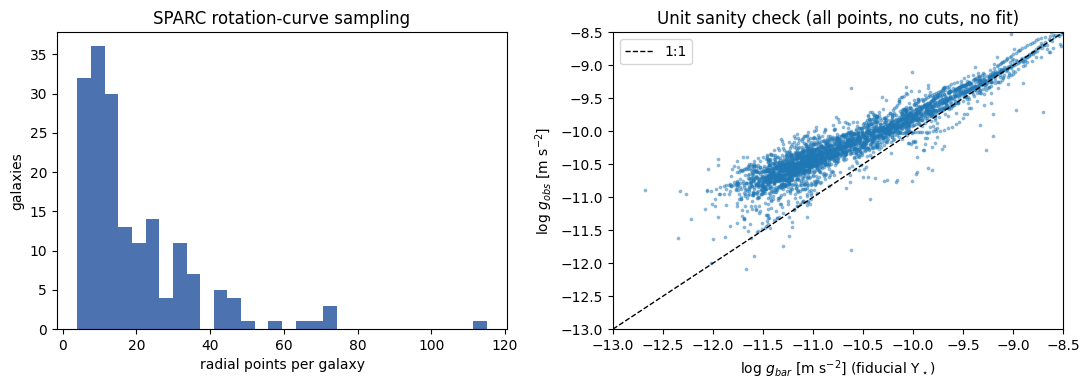

This plot only checks that units and magnitudes are sensible. It is not a fit and not a result.


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(gsum["n_points_rotmod"], bins=30, color="#4C72B0")
ax[0].set_xlabel("radial points per galaxy"); ax[0].set_ylabel("galaxies"); ax[0].set_title("SPARC rotation-curve sampling")
ok = (p["g_bar_ms2_derived_fid"] > 0) & (p["g_obs_ms2_derived"] > 0)
ax[1].scatter(np.log10(p.loc[ok, "g_bar_ms2_derived_fid"]), np.log10(p.loc[ok, "g_obs_ms2_derived"]), s=3, alpha=0.4)
lims = [-13, -8.5]; ax[1].plot(lims, lims, "k--", lw=1, label="1:1")
ax[1].set_xlim(lims); ax[1].set_ylim(lims)
ax[1].set_xlabel(r"log $g_{bar}$ [m s$^{-2}$] (fiducial $\Upsilon_\star$)"); ax[1].set_ylabel(r"log $g_{obs}$ [m s$^{-2}$]")
ax[1].set_title("Unit sanity check (all points, no cuts, no fit)"); ax[1].legend()
plt.tight_layout()
fig.savefig(FIGURES_DIR / "01_sparc_sampling_and_unit_check.png", dpi=150)
plt.show()
print("This plot only checks that units and magnitudes are sensible. It is not a fit and not a result.")

## 7. Quality Cuts and Inclusion/Exclusion

Applies exactly the cuts fixed in the proposal: **Q ≤ 2** and **inclination ≥ 30°**. Galaxies are also excluded if they have no parseable rotation-curve file or no MRT entry (needed to evaluate the cuts). No point-level cuts are applied: the proposal defines none, and flagged points are only reported.

In [17]:
def exclusion_reasons(row):
    r = []
    if not row["in_mrt"]:
        r.append("no MRT entry (Q and inclination unknown)")
    else:
        if pd.isna(row["quality_flag_Q"]):
            r.append("Q missing")
        elif row["quality_flag_Q"] > Q_MAX:
            r.append(f"Q={int(row['quality_flag_Q'])} > {Q_MAX}")
        if pd.isna(row["inc_deg"]):
            r.append("inclination missing")
        elif row["inc_deg"] < INC_MIN_DEG:
            r.append(f"inc={row['inc_deg']:.1f} deg < {INC_MIN_DEG:.0f}")
    if not row["has_rotmod_file"]:
        r.append("no rotmod file")
    elif not row["rotmod_parse_ok"]:
        r.append("rotmod file could not be parsed")
    return "; ".join(r)

sga = sparc_galaxy_audit
sga["exclusion_reasons"] = sga.apply(exclusion_reasons, axis=1)
sga["passes_quality_cuts"] = sga["exclusion_reasons"] == ""
sga["fails_Q"]   = sga["quality_flag_Q"].gt(Q_MAX).fillna(False)
sga["fails_inc"] = sga["inc_deg"].lt(INC_MIN_DEG).fillna(False)
sga["n_points_rotmod"] = sga["n_points_rotmod"].fillna(0).astype(int)

passing = set(sga.loc[sga.passes_quality_cuts, "galaxy"])
p["galaxy_passes_quality_cuts"] = p["galaxy"].isin(passing)

steps = [
    ("All galaxies (MRT ∪ rotmod files)", sga),
    ("In MRT", sga[sga.in_mrt]),
    ("…with a parseable rotmod file", sga[sga.in_mrt & sga.rotmod_parse_ok]),
    (f"…and Q ≤ {Q_MAX}", sga[sga.in_mrt & sga.rotmod_parse_ok & ~sga.fails_Q & sga.quality_flag_Q.notna()]),
    (f"…and inc ≥ {INC_MIN_DEG:.0f}° (final sample)", sga[sga.passes_quality_cuts]),
]
quality_summary = pd.DataFrame([{"step": s, "n_galaxies": len(d), "n_radial_points": int(d["n_points_rotmod"].sum())}
                                for s, d in steps])
breakdown = pd.DataFrame([
    {"step": "Excluded: Q > 2 only", "n_galaxies": int((sga.fails_Q & ~sga.fails_inc).sum()),
     "n_radial_points": int(sga.loc[sga.fails_Q & ~sga.fails_inc, "n_points_rotmod"].sum())},
    {"step": "Excluded: inc < 30° only", "n_galaxies": int((~sga.fails_Q & sga.fails_inc).sum()),
     "n_radial_points": int(sga.loc[~sga.fails_Q & sga.fails_inc, "n_points_rotmod"].sum())},
    {"step": "Excluded: both Q and inc", "n_galaxies": int((sga.fails_Q & sga.fails_inc).sum()),
     "n_radial_points": int(sga.loc[sga.fails_Q & sga.fails_inc, "n_points_rotmod"].sum())},
    {"step": "Excluded: missing MRT entry or rotmod file", "n_galaxies": int((~sga.in_mrt | ~sga.rotmod_parse_ok).sum()),
     "n_radial_points": int(sga.loc[~sga.in_mrt | ~sga.rotmod_parse_ok, "n_points_rotmod"].sum())},
])
sparc_quality_cut_summary = pd.concat([quality_summary, breakdown], ignore_index=True)
sparc_quality_cut_summary["criteria"] = f"Q <= {Q_MAX}; inc >= {INC_MIN_DEG} deg (proposal Section 3)"
display(sparc_quality_cut_summary)

n_pass_gal, n_pass_pts = len(passing), int(p["galaxy_passes_quality_cuts"].sum())
n_flag_in_pass = int(p.loc[p.galaxy_passes_quality_cuts, critical_point_flags].any(axis=1).sum())
print(f"Final SPARC sample after proposal cuts: {n_pass_gal} galaxies, {n_pass_pts} radial points.")
print(f"Flagged points inside the final sample (reported, not removed): {n_flag_in_pass}")
record_check("SPARC cuts", "final sample is non-empty", n_pass_gal > 0, f"{n_pass_gal} galaxies")
record_check("SPARC cuts", "point counts consistent (sum of per-galaxy counts)",
             n_pass_pts == int(sga.loc[sga.passes_quality_cuts, "n_points_rotmod"].sum()), f"{n_pass_pts} points")

excluded_log = sga.loc[~sga.passes_quality_cuts, ["galaxy", "quality_flag_Q", "inc_deg", "has_rotmod_file",
                                                    "n_points_rotmod", "exclusion_reasons"]].sort_values("galaxy")
for _, r in excluded_log.iterrows():
    logger.info(f"EXCLUDED {r.galaxy}: {r.exclusion_reasons}")
display(excluded_log)

,step,n_galaxies,n_radial_points,criteria
0,All galaxies (MRT ∪ rotmod files),175,3391,Q <= 2; inc >= 30.0 deg (proposal Section 3)
1,In MRT,175,3391,Q <= 2; inc >= 30.0 deg (proposal Section 3)
2,…with a parseable rotmod file,175,3391,Q <= 2; inc >= 30.0 deg (proposal Section 3)
3,…and Q ≤ 2,163,3271,Q <= 2; inc >= 30.0 deg (proposal Section 3)
4,…and inc ≥ 30° (final sample),153,3168,Q <= 2; inc >= 30.0 deg (proposal Section 3)
5,Excluded: Q > 2 only,10,109,Q <= 2; inc >= 30.0 deg (proposal Section 3)
6,Excluded: inc < 30° only,10,103,Q <= 2; inc >= 30.0 deg (proposal Section 3)
7,Excluded: both Q and inc,2,11,Q <= 2; inc >= 30.0 deg (proposal Section 3)
8,Excluded: missing MRT entry or rotmod file,0,0,Q <= 2; inc >= 30.0 deg (proposal Section 3)


Final SPARC sample after proposal cuts: 153 galaxies, 3168 radial points.
Flagged points inside the final sample (reported, not removed): 0
INFO: [PASS] SPARC cuts | final sample is non-empty | 153 galaxies


INFO:rar_audit:[PASS] SPARC cuts | final sample is non-empty | 153 galaxies


INFO: [PASS] SPARC cuts | point counts consistent (sum of per-galaxy counts) | 3168 points


INFO:rar_audit:[PASS] SPARC cuts | point counts consistent (sum of per-galaxy counts) | 3168 points


...

INFO: EXCLUDED UGC07608: inc=25.0 deg < 30


INFO:rar_audit:EXCLUDED UGC07608: inc=25.0 deg < 30


INFO: EXCLUDED UGCA281: Q=3 > 2


INFO:rar_audit:EXCLUDED UGCA281: Q=3 > 2


,galaxy,quality_flag_Q,inc_deg,has_rotmod_file,n_points_rotmod,exclusion_reasons
13,F561-1,3,24.0,True,6,Q=3 > 2; inc=24.0 deg < 30
14,F563-1,1,25.0,True,17,inc=25.0 deg < 30
15,F563-V1,3,60.0,True,6,Q=3 > 2
16,F563-V2,1,29.0,True,10,inc=29.0 deg < 30
18,F567-2,3,20.0,True,5,Q=3 > 2; inc=20.0 deg < 30
19,F568-1,1,26.0,True,12,inc=26.0 deg < 30
25,F574-2,3,30.0,True,5,Q=3 > 2
26,F579-V1,1,26.0,True,14,inc=26.0 deg < 30
42,NGC1705,3,80.0,True,14,Q=3 > 2
43,NGC2366,3,68.0,True,26,Q=3 > 2


## 8. Unified HI Corpus Audit

The README is read first to record what the corpus *documents*. The JSON and CSV structures are then discovered from the files themselves and compared with that documentation. The JSON is treated as authoritative, as the README states.

In [18]:
readme_text = UNIFIED_README.read_text(encoding="utf-8", errors="replace")
readme_headings = [l.strip() for l in readme_text.splitlines() if l.lstrip().startswith("#")]
print(f"README: {len(readme_text)} characters, {len(readme_headings)} headings")
for h in readme_headings:
    print("  ", h)

# Documented per-ring columns, if the README contains the per-survey markdown table.
documented_cols = {}
for l in readme_text.splitlines():
    if l.strip().startswith("|") and "`data`" in l:
        cells = [c.strip() for c in l.strip().strip("|").split("|")]
        if len(cells) >= 3:
            survey_label = re.sub(r"\(.*?\)", "", cells[0]).strip().upper().replace(" ", "_")
            documented_cols[survey_label] = [c.strip() for c in cells[2].split(",")]
if documented_cols:
    print("\nPer-ring columns documented in the README:")
    for k, v in documented_cols.items():
        print(f"   {k}: {v}")
else:
    print("\nNo per-survey column table found in the README; documented-vs-observed comparison skipped.")

README: 18470 characters, 30 headings
   # Unified Galaxy HI Rotation Curve Corpus (v7.0)
   ## 1. Summary
   ## 2. What You Can Do With This Data
   ### Minimal Plotting Example (Python, JSON)
   ### RAG Pipeline Example (Python, JSONL)
   # Load all 438 galaxies into a list without reading the full JSON into memory
   # Filter to omega-ready SPARC galaxies
   ## 3. Survey Coverage
   ## 4. Quality Tiers
   ## 5. Files
   ### 5.1 rotation_curve_corpus_v7.json — Master JSON (Primary Deliverable)
   ### 5.2 rotation_curve_corpus_v7.jsonl — RAG Corpus (New in v7.0)
   ### 5.3 rotation_curve_corpus_v7_flat.csv — Catalog Table
   ### 5.4 rotation_curve_corpus_v7_flat.xlsx — Catalog Table (Excel)
   ### 5.5 rotation_curve_corpus_v7_by_galaxy.zip — Per-Galaxy JSON Files
   ### 5.6 Scripts
   ## 6. Flat CSV/XLSX Schema (38 Columns)
   ## 7. Key Conventions
   ### 7.1 Radii
   ### 7.2 SPARC Baryonic Velocities and Quadrature Convention
   ### 7.3 WALLABY Velocities
   ### 7.4 Omega Correction


In [19]:
with open(UNIFIED_JSON, "r", encoding="utf-8") as fh:
    corpus = json.load(fh)

print("Top-level JSON type:", type(corpus).__name__)
if isinstance(corpus, dict):
    for k, v in corpus.items():
        print(f"  key '{k}': {type(v).__name__}" + (f" (len {len(v)})" if hasattr(v, "__len__") else ""))
    list_keys = [k for k, v in corpus.items() if isinstance(v, list) and v and all(isinstance(x, dict) for x in v)]
    if not list_keys:
        raise ValueError("JSON has no list of galaxy objects at the top level.")
    GAL_KEY = "galaxies" if "galaxies" in list_keys else max(list_keys, key=lambda k: len(corpus[k]))
    galaxies_json = corpus[GAL_KEY]
    corpus_metadata = corpus.get("metadata", {})
elif isinstance(corpus, list):
    GAL_KEY, galaxies_json, corpus_metadata = None, corpus, {}
else:
    raise ValueError(f"Unexpected JSON top-level type {type(corpus).__name__}")
print(f"\nGalaxy records: {len(galaxies_json)} (key: {GAL_KEY})")
if corpus_metadata:
    print("Metadata keys:", list(corpus_metadata))
    for k in ("version", "total_galaxies", "surveys", "last_updated"):
        if k in corpus_metadata:
            print(f"  {k}: {corpus_metadata[k]}")

# Inventory of galaxy-level keys and value types
key_types = {}
for g in galaxies_json:
    for k, v in g.items():
        key_types.setdefault(k, set()).add(type(v).__name__)
print("\nGalaxy-level keys and value types observed:")
for k, t in sorted(key_types.items()):
    print(f"  {k}: {sorted(t)}")

Top-level JSON type: dict
  key 'metadata': dict (len 9)
  key 'galaxies': list (len 438)

Galaxy records: 438 (key: galaxies)
Metadata keys: ['version', 'total_galaxies', 'surveys', 'last_updated', 'description', 'quality_tiers', 'citation', 'provenance', 'version_notes']
  version: 7.0
  total_galaxies: 438
  surveys: {'SPARC': 175, 'THINGS': 34, 'LITTLE_THINGS': 26, 'WALLABY': 203}
  last_updated: 2026-04-13

Galaxy-level keys and value types observed:
  R0.3_kpc: ['float']
  V0.3_kms: ['float']
  beam_arcsec: ['NoneType', 'float']
  citation: ['str']
  columns: ['dict']
  corpus_source: ['str']
  corpus_version: ['str']
  data: ['list']
  data_source: ['str']
  dec_deg: ['NoneType', 'float']
  distance_mpc: ['float']
  e_distance_mpc: ['float']
  e_inc_deg: ['float']
  galaxy: ['str']
  has_bulge: ['bool']
  hubble_type: ['float']
  inc_deg: ['float']
  ingested_date: ['str']
  known_issues: ['list']
  m2l_disk: ['float']
  n_points: ['float', 'int']
  notes: ['str']
  pa_deg: ['No

In [20]:
def as_bool(v):
    # JSON booleans may arrive as bool, number or text; anything unrecognised is None (unknown).
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return None
    if isinstance(v, (bool, np.bool_)):
        return bool(v)
    if isinstance(v, (int, float, np.integer, np.floating)):
        return bool(v)
    t = str(v).strip().lower()
    return True if t in ("true", "t", "yes", "1") else False if t in ("false", "f", "no", "0") else None

def canonical_survey(s):
    s = str(s).strip().upper().replace(" ", "_").replace("-", "_")
    if "LITTLE" in s: return "LITTLE_THINGS"
    if s.startswith("WALLABY"): return "WALLABY"
    if s == "THINGS": return "THINGS"
    if s == "SPARC": return "SPARC"
    return s

# Which key holds the per-ring data? Discovered, with documented fallbacks.
DATA_KEY_CANDIDATES = ["data", "rotation_curve", "points", "rc"]
def get_points(g):
    for k in DATA_KEY_CANDIDATES:
        if k in g and isinstance(g[k], list):
            return k, g[k]
    return None, []

# Roles for per-ring columns and galaxy-level fields, matched against the keys actually present.
POINT_ROLES = {
    "radius": ["Rad", "rad_kpc", "R", "radius_kpc"],
    "velocity": ["Vobs", "Vrot", "vrot_kms"],
    "velocity_error": ["errV", "e_Vrot", "e_Vobs", "err_Vrot", "eVrot", "e_V"],
    "vgas": ["Vgas"], "vdisk": ["Vdisk"], "vbul": ["Vbul"],
    "sbdisk": ["SBdisk"], "sbbul": ["SBbul"], "vdisp": ["Vdisp", "vdisp_kms"],
}
GAL_ROLES = {
    "distance": ["distance_mpc", "distance", "D_Mpc", "dist_mpc"],
    "e_distance": ["e_distance_mpc"],
    "inclination": ["inc_deg", "inclination", "inc"],
    "e_inclination": ["e_inc_deg"],
    "ra": ["ra_deg", "ra"], "dec": ["dec_deg", "dec"],
    "ml_info": ["m2l_disk", "upsilon_disk", "ml_disk"],
    "has_bulge": ["has_bulge"], "has_stellar_mass": ["has_stellar_mass"],
    "has_vgas_profile": ["has_vgas_profile"], "quality_tier": ["quality_tier"],
    "n_points_field": ["n_points"],
}
def _num(v):
    try:
        x = float(v)
        return x if np.isfinite(x) else None
    except (TypeError, ValueError):
        return None

def first_key(d, cands):
    return next((c for c in cands if c in d and d[c] is not None and not (isinstance(d[c], float) and np.isnan(d[c]))), None)

point_rows, gal_rows = [], []
for gi, g in enumerate(galaxies_json):
    name = str(g.get("galaxy", g.get("name", f"__unnamed_{gi}")))
    survey = canonical_survey(g.get("survey", "UNKNOWN"))
    dkey, pts = get_points(g)
    pkeys = sorted({k for pt in pts if isinstance(pt, dict) for k in pt})
    row = {"record_index": gi, "galaxy": name, "survey": survey, "data_key": dkey,
           "n_points_actual": len(pts), "point_columns": ",".join(pkeys)}
    for k, v in g.items():                         # all scalar galaxy-level fields, as stored
        if not isinstance(v, (list, dict)):
            row[f"json_{k}"] = v
    for role, cands in GAL_ROLES.items():
        key = first_key(g, cands)
        row[f"gal_{role}_key"] = key
        row[f"gal_{role}"] = g.get(key) if key else None
    for role, cands in POINT_ROLES.items():
        key = next((c for c in cands if c in pkeys), None)
        vals = [_num(pt.get(key)) for pt in pts] if key else []
        n_valid = sum(v is not None for v in vals)
        row[f"pt_{role}_key"] = key
        row[f"pt_{role}_n_valid"] = n_valid
        row[f"has_{role}"] = bool(key) and n_valid == len(pts) and len(pts) > 0
        if role == "velocity_error" and key:
            row["n_velocity_error_nonpositive"] = sum(v is not None and v <= 0 for v in vals)
    # other columns that look like uncertainties, so differently named error columns are not missed
    row["other_error_like_columns"] = ",".join(k for k in pkeys if (k.lower().startswith("e_") or "err" in k.lower())
                                               and k not in POINT_ROLES["velocity_error"])
    rk = row["pt_radius_key"]
    if rk:
        radii = [_num(pt.get(rk)) for pt in pts]
        rr = [r for r in radii if r is not None]
        row["n_duplicate_radii"] = len(rr) - len(set(rr))
        row["n_nonpositive_radii"] = sum(r <= 0 for r in rr)
    else:
        row["n_duplicate_radii"] = row["n_nonpositive_radii"] = None
    row["n_null_point_values"] = sum(v is None for pt in pts for v in pt.values())
    gal_rows.append(row)
    for pi, pt in enumerate(pts):
        point_rows.append({"galaxy": name, "survey": survey, "point_index": pi, **pt})

unified_gal = pd.DataFrame(gal_rows)
unified_pts = pd.DataFrame(point_rows)
unified_gal["has_coordinates"] = unified_gal["gal_ra"].map(_num).notna() & unified_gal["gal_dec"].map(_num).notna()
unified_gal["has_distance"] = unified_gal["gal_distance"].map(_num).notna()
unified_gal["has_inclination"] = unified_gal["gal_inclination"].map(_num).notna()
nf = unified_gal["gal_n_points_field"].map(_num)
unified_gal["n_points_field_matches"] = nf.isna() | (nf == unified_gal["n_points_actual"])

print("Surveys found:", unified_gal["survey"].value_counts().to_dict())
unknown = sorted(set(unified_gal.survey) - {"SPARC", "THINGS", "LITTLE_THINGS", "WALLABY"})
record_check("Unified JSON", "only the four documented surveys present", not unknown, unknown or "ok", severity="warning")
dup_ids = unified_gal[unified_gal.duplicated(["galaxy", "survey"], keep=False)]
record_check("Unified JSON", "galaxy identifiers unique within each survey", dup_ids.empty,
             dup_ids[["galaxy", "survey"]].values.tolist() if not dup_ids.empty else "unique")
record_check("Unified JSON", "n_points field equals length of data array",
             bool(unified_gal["n_points_field_matches"].all()),
             f"{int((~unified_gal['n_points_field_matches']).sum())} mismatches", severity="warning")

Surveys found: {'WALLABY': 203, 'SPARC': 175, 'THINGS': 34, 'LITTLE_THINGS': 26}
INFO: [PASS] Unified JSON | only the four documented surveys present | ok


INFO:rar_audit:[PASS] Unified JSON | only the four documented surveys present | ok


INFO: [PASS] Unified JSON | galaxy identifiers unique within each survey | unique


INFO:rar_audit:[PASS] Unified JSON | galaxy identifiers unique within each survey | unique


INFO: [PASS] Unified JSON | n_points field equals length of data array | 0 mismatches


INFO:rar_audit:[PASS] Unified JSON | n_points field equals length of data array | 0 mismatches


True

In [21]:
# Per-survey summary: what each survey actually provides
def frac(s): return round(float(s.mean()), 3) if len(s) else np.nan
srows = []
for sv, d in unified_gal.groupby("survey"):
    observed = sorted({c for cols in d["point_columns"] for c in cols.split(",") if c})
    srows.append({
        "survey": sv, "n_entries": len(d), "n_with_points": int((d.n_points_actual > 0).sum()),
        "n_without_points": int((d.n_points_actual == 0).sum()), "n_points_total": int(d.n_points_actual.sum()),
        "observed_point_columns": ", ".join(observed),
        "documented_point_columns": ", ".join(documented_cols.get(sv, [])) or "(not documented)",
        "frac_with_radius": frac(d.has_radius), "frac_with_velocity": frac(d.has_velocity),
        "frac_with_velocity_error": frac(d.has_velocity_error),
        "frac_with_vgas": frac(d.has_vgas), "frac_with_vdisk": frac(d.has_vdisk), "frac_with_vbul": frac(d.has_vbul),
        "frac_with_distance": frac(d.has_distance), "frac_with_inclination": frac(d.has_inclination),
        "frac_with_coordinates": frac(d.has_coordinates),
        "frac_with_ml_info": frac(d.gal_ml_info.map(_num).notna()),
        "n_galaxies_with_duplicate_radii": int((d.n_duplicate_radii.fillna(0) > 0).sum()),
        "n_null_point_values": int(d.n_null_point_values.sum()),
        "n_points_field_mismatch": int((~d.n_points_field_matches).sum()),
        "quality_tiers": ", ".join(sorted({str(x) for x in d.gal_quality_tier.dropna()})),
    })
unified_survey_summary = pd.DataFrame(srows).sort_values("survey").reset_index(drop=True)
display(unified_survey_summary.T)

# Documented vs observed columns
for sv in unified_survey_summary.survey:
    doc = set(documented_cols.get(sv, []))
    obs = set(unified_survey_summary.loc[unified_survey_summary.survey == sv, "observed_point_columns"].iloc[0].split(", ")) - {""}
    if doc:
        record_check("Unified JSON", f"{sv}: observed per-ring columns match README", doc == obs,
                     f"documented {sorted(doc)}; observed {sorted(obs)}", severity="warning")

# Explicit statement on baryonic components outside SPARC
non_sparc = unified_gal[unified_gal.survey != "SPARC"]
n_bary = int((non_sparc.has_vgas | non_sparc.has_vdisk).sum())
print(f"\nNon-SPARC records with any baryonic velocity component in the corpus: {n_bary} of {len(non_sparc)}")

,0,1,2,3
survey,LITTLE_THINGS,SPARC,THINGS,WALLABY
n_entries,26,175,34,203
n_with_points,26,175,19,203
n_without_points,0,0,15,0
n_points_total,1716,3391,2110,1746
observed_point_columns,"Rad, Vobs, errV","Rad, SBbul, SBdisk, Vbul, Vdisk, Vgas, Vobs, errV","Rad, Vrot, e_Vrot","Rad, Vdisp, Vrot"
documented_point_columns,"Rad, Vrot, errV","Rad, Vobs, errV, Vgas, Vdisk, Vbul, SBdisk, SBbul","Rad, Vrot, e_Vrot","Rad, Vrot, Vdisp"
frac_with_radius,1.0,1.0,0.559,1.0
frac_with_velocity,1.0,1.0,0.559,1.0
frac_with_velocity_error,0.962,1.0,0.559,0.0


INFO: [PASS] Unified JSON | SPARC: observed per-ring columns match README | documented ['Rad', 'SBbul', 'SBdisk', 'Vbul', 'Vdisk', 'Vgas', 'Vobs', 'errV']; observed ['Rad', 'SBbul', 'SBdisk', 'Vbul', 'Vdisk', 'Vgas', 'Vobs', 'errV']


INFO:rar_audit:[PASS] Unified JSON | SPARC: observed per-ring columns match README | documented ['Rad', 'SBbul', 'SBdisk', 'Vbul', 'Vdisk', 'Vgas', 'Vobs', 'errV']; observed ['Rad', 'SBbul', 'SBdisk', 'Vbul', 'Vdisk', 'Vgas', 'Vobs', 'errV']


INFO: [PASS] Unified JSON | THINGS: observed per-ring columns match README | documented ['Rad', 'Vrot', 'e_Vrot']; observed ['Rad', 'Vrot', 'e_Vrot']


INFO:rar_audit:[PASS] Unified JSON | THINGS: observed per-ring columns match README | documented ['Rad', 'Vrot', 'e_Vrot']; observed ['Rad', 'Vrot', 'e_Vrot']


INFO: [PASS] Unified JSON | WALLABY: observed per-ring columns match README | documented ['Rad', 'Vdisp', 'Vrot']; observed ['Rad', 'Vdisp', 'Vrot']


INFO:rar_audit:[PASS] Unified JSON | WALLABY: observed per-ring columns match README | documented ['Rad', 'Vdisp', 'Vrot']; observed ['Rad', 'Vdisp', 'Vrot']



Non-SPARC records with any baryonic velocity component in the corpus: 0 of 263


In [22]:
# Flat CSV: schema, types, missing values, and consistency with the JSON
flat = pd.read_csv(UNIFIED_CSV)
print(f"Flat CSV: {flat.shape[0]} rows x {flat.shape[1]} columns")
schema = pd.DataFrame({"dtype": flat.dtypes.astype(str), "n_non_null": flat.notna().sum(),
                       "n_null": flat.isna().sum()})
display(schema)
for col in ("galaxy", "survey"):
    record_check("Unified CSV", f"column '{col}' present", col in flat.columns, list(flat.columns)[:10])
if {"galaxy", "survey"} <= set(flat.columns):
    flat["survey_canon"] = flat["survey"].map(canonical_survey)
    display(flat["survey_canon"].value_counts().to_frame("n_rows"))
    js = set(zip(unified_gal.galaxy, unified_gal.survey))
    cs = set(zip(flat.galaxy.astype(str), flat.survey_canon))
    record_check("Unified CSV", "same (galaxy, survey) set as JSON", js == cs,
                 f"JSON only: {sorted(js - cs)[:10]}; CSV only: {sorted(cs - js)[:10]}", severity="warning")
    if "n_points" in flat.columns:
        m = flat.merge(unified_gal[["galaxy", "survey", "n_points_actual"]],
                       left_on=["galaxy", "survey_canon"], right_on=["galaxy", "survey"], how="inner")
        mism = m[pd.to_numeric(m.n_points, errors="coerce") != m.n_points_actual]
        record_check("Unified CSV", "n_points agrees with JSON data arrays", mism.empty,
                     mism[["galaxy", "survey_canon", "n_points", "n_points_actual"]].head(10).values.tolist()
                     if not mism.empty else f"{len(m)} rows compared", severity="warning")
readme_38 = re.search(r"\((\d+)\s*Columns\)", readme_text)
if readme_38:
    record_check("Unified CSV", "column count matches README description", int(readme_38.group(1)) == flat.shape[1],
                 f"README says {readme_38.group(1)}, file has {flat.shape[1]} (v7.1 CSV vs v7.0 README)", severity="warning")

Flat CSV: 438 rows x 30 columns


,dtype,n_non_null,n_null
galaxy,object,438,0
survey,object,438,0
quality_tier,int64,438,0
telescope,object,263,175
ra_deg,float64,263,175
dec_deg,float64,263,175
distance_mpc,float64,438,0
e_distance_mpc,float64,175,263
vsys_kms,float64,263,175
inc_deg,float64,438,0


INFO: [PASS] Unified CSV | column 'galaxy' present | ['galaxy', 'survey', 'quality_tier', 'telescope', 'ra_deg', 'dec_deg', 'distance_mpc', 'e_distance_mpc', 'vsys_kms', 'inc_deg']


INFO:rar_audit:[PASS] Unified CSV | column 'galaxy' present | ['galaxy', 'survey', 'quality_tier', 'telescope', 'ra_deg', 'dec_deg', 'distance_mpc', 'e_distance_mpc', 'vsys_kms', 'inc_deg']


INFO: [PASS] Unified CSV | column 'survey' present | ['galaxy', 'survey', 'quality_tier', 'telescope', 'ra_deg', 'dec_deg', 'distance_mpc', 'e_distance_mpc', 'vsys_kms', 'inc_deg']


INFO:rar_audit:[PASS] Unified CSV | column 'survey' present | ['galaxy', 'survey', 'quality_tier', 'telescope', 'ra_deg', 'dec_deg', 'distance_mpc', 'e_distance_mpc', 'vsys_kms', 'inc_deg']


,n_rows
survey_canon,
WALLABY,203
SPARC,175
THINGS,34
LITTLE_THINGS,26


INFO: [PASS] Unified CSV | same (galaxy, survey) set as JSON | JSON only: []; CSV only: []


INFO:rar_audit:[PASS] Unified CSV | same (galaxy, survey) set as JSON | JSON only: []; CSV only: []


In [23]:
# Cross-check: corpus SPARC entries vs the original SPARC rotmod files
cs_sparc = unified_gal[unified_gal.survey == "SPARC"][["galaxy", "n_points_actual"]]
cmp = cs_sparc.merge(gsum[["galaxy", "n_points_rotmod"]], on="galaxy", how="outer", indicator=True)
only_corpus = sorted(cmp.loc[cmp._merge == "left_only", "galaxy"])
only_orig = sorted(cmp.loc[cmp._merge == "right_only", "galaxy"])
both = cmp[cmp._merge == "both"]
npt_diff = both[both.n_points_actual != both.n_points_rotmod]
record_check("Corpus vs SPARC", "corpus SPARC names match rotmod names", not only_corpus and not only_orig,
             f"corpus only: {only_corpus[:10]}; rotmod only: {only_orig[:10]}", severity="warning")
record_check("Corpus vs SPARC", "corpus SPARC point counts match rotmod files", npt_diff.empty,
             npt_diff[["galaxy", "n_points_actual", "n_points_rotmod"]].head(10).values.tolist() if not npt_diff.empty
             else f"{len(both)} galaxies compared", severity="warning")
# Bulge flag consistency
if "gal_has_bulge" in unified_gal:
    hb = unified_gal[unified_gal.survey == "SPARC"][["galaxy", "gal_has_bulge"]].merge(
        gsum[["galaxy", "has_bulge_component"]], on="galaxy")
    hb["corpus_flag"] = hb.gal_has_bulge.map(as_bool)
    hb_bad = hb[hb.corpus_flag.notna() & (hb.corpus_flag != hb.has_bulge_component)]
    record_check("Corpus vs SPARC", "corpus has_bulge agrees with Vbul > 0 in rotmod files", hb_bad.empty,
                 hb_bad.values.tolist()[:10] if not hb_bad.empty else f"{len(hb)} compared", severity="warning")

INFO: [PASS] Corpus vs SPARC | corpus SPARC names match rotmod names | corpus only: []; rotmod only: []


INFO:rar_audit:[PASS] Corpus vs SPARC | corpus SPARC names match rotmod names | corpus only: []; rotmod only: []


INFO: [PASS] Corpus vs SPARC | corpus SPARC point counts match rotmod files | 175 galaxies compared


INFO:rar_audit:[PASS] Corpus vs SPARC | corpus SPARC point counts match rotmod files | 175 galaxies compared


INFO: [PASS] Corpus vs SPARC | corpus has_bulge agrees with Vbul > 0 in rotmod files | 175 compared


INFO:rar_audit:[PASS] Corpus vs SPARC | corpus has_bulge agrees with Vbul > 0 in rotmod files | 175 compared


## 9. Cross-Survey Duplicate Detection

Galaxies that appear in more than one survey are found three ways, and **no record is deleted**:

1. **Normalised names:** upper-case, spaces/underscores/hyphens removed, leading zeros stripped from number groups (e.g. `NGC0024` → `NGC24`, `DDO 154` → `DDO154`).
2. **Alias table:** a short list of standard catalogue cross-identifications (e.g. Holmberg II = DDO 50 = UGC 4305). Every alias-based match is marked for manual review; confirm each in NED before relying on it.
3. **Positions:** angular separation where both records have coordinates. SPARC records carry no coordinates in this corpus (README Section 7.5), so SPARC matches rely on names and aliases only.

Tolerances: ≤ 30″ is treated as a positional match; 30–120″ is flagged as ambiguous for manual review.

In [24]:
def normalise_name(n):
    s = str(n).upper().strip()
    s = re.sub(r"[\s_\-\.]+", "", s)
    s = re.sub(r"(?<![0-9])0+(?=[0-9])", "", s)     # strip leading zeros in every number group
    return s

# Standard cross-identifications (each group = one galaxy). Used ONLY to propose candidates for review.
ALIAS_GROUPS = [
    ["HOII", "HOLMBERGII", "DDO50", "UGC4305"],
    ["HOI", "HOLMBERGI", "DDO63", "UGC5139"],
    ["IC2574", "DDO81", "UGC5666"],
    ["NGC2366", "DDO42", "UGC3851"],
    ["NGC4214", "UGC7278"],
    ["DDO154", "UGC8024"],
    ["DDO168", "UGC8320"],
    ["DDO126", "UGC7559"],
    ["DDO87", "UGC5918"],
    ["DDO133", "UGC7698"],
    ["DDO216", "UGC12613", "PEGASUSDWARF"],
    ["DDO53", "UGC4459"],
    ["DDO70", "UGC5373", "SEXTANSB"],
    ["CVNIDWA", "UGCA292"],
    ["WLM", "DDO221"],
    ["NGC3031", "M81"], ["NGC5194", "M51"], ["NGC5236", "M83"], ["NGC5457", "M101"],
]
ALIAS_OF = {a: i for i, grp in enumerate(ALIAS_GROUPS) for a in grp}

# Records to compare: every unified-corpus entry (including its SPARC copies) plus the original SPARC MRT list.
recs = unified_gal[["galaxy", "survey", "gal_ra", "gal_dec", "gal_distance", "gal_inclination", "n_points_actual"]].copy()
recs["source"] = "unified_json"
mrt_recs = sparc_gal[["galaxy", "distance_mpc", "inc_deg"]].rename(
    columns={"distance_mpc": "gal_distance", "inc_deg": "gal_inclination"})
mrt_recs = mrt_recs.assign(survey="SPARC_MRT", gal_ra=None, gal_dec=None, source="sparc_mrt",
                           n_points_actual=mrt_recs["galaxy"].map(gsum.set_index("galaxy")["n_points_rotmod"]))
recs = pd.concat([recs, mrt_recs], ignore_index=True)
recs["norm"] = recs["galaxy"].map(normalise_name)
recs["alias_group"] = recs["norm"].map(ALIAS_OF)
recs["ra"] = recs["gal_ra"].map(_num); recs["dec"] = recs["gal_dec"].map(_num)
recs = recs.reset_index(drop=True)

def ang_sep_arcsec(ra1, dec1, ra2, dec2):
    ra1, dec1, ra2, dec2 = map(np.radians, (ra1, dec1, ra2, dec2))
    h = np.sin((dec2 - dec1) / 2) ** 2 + np.cos(dec1) * np.cos(dec2) * np.sin((ra2 - ra1) / 2) ** 2
    return np.degrees(2 * np.arcsin(np.sqrt(np.clip(h, 0, 1)))) * 3600

def same_dataset(sa, sb):
    # The corpus SPARC copy and the original MRT are the same survey; their pairing is a consistency check.
    group = lambda s: "SPARC" if s in ("SPARC", "SPARC_MRT") else s
    return group(sa) == group(sb)

pairs = {}
def add_pair(i, j, method):
    a, b = sorted((i, j))
    pairs.setdefault((a, b), set()).add(method)

for _, grp in recs.groupby("norm"):
    idx = list(grp.index)
    for x in range(len(idx)):
        for y in range(x + 1, len(idx)):
            add_pair(idx[x], idx[y], "normalised_name")
for _, grp in recs.dropna(subset=["alias_group"]).groupby("alias_group"):
    idx = list(grp.index)
    for x in range(len(idx)):
        for y in range(x + 1, len(idx)):
            if recs.at[idx[x], "norm"] != recs.at[idx[y], "norm"]:
                add_pair(idx[x], idx[y], "alias_table")
pos = recs.dropna(subset=["ra", "dec"])
if len(pos) > 1:
    P = pos[["ra", "dec"]].to_numpy()
    for x in range(len(pos)):
        seps = ang_sep_arcsec(P[x, 0], P[x, 1], P[x + 1:, 0], P[x + 1:, 1])
        for k in np.where(seps <= POS_TOL_REVIEW_ARCSEC)[0]:
            add_pair(pos.index[x], pos.index[x + 1 + k], "position")
print(f"Candidate pairs before classification: {len(pairs)}")

/tmp/ipykernel_5902/848012670.py:35: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  recs = pd.concat([recs, mrt_recs], ignore_index=True)


Candidate pairs before classification: 222


In [25]:
def velocity_key(survey_name, galaxy_name):
    row = unified_gal[(unified_gal.galaxy == galaxy_name) & (unified_gal.survey == survey_name)]
    if row.empty:
        return None, None
    return row.iloc[0]["pt_radius_key"], row.iloc[0]["pt_velocity_key"]

def curve(survey_name, galaxy_name):
    # Returns (R, V) for a record; duplicate radii (e.g. approaching/receding halves) are averaged.
    if survey_name == "SPARC_MRT":
        t = rot_tables.get(galaxy_name)
        return (None, None) if t is None else (t["Rad"].to_numpy(float), t["Vobs"].to_numpy(float))
    rk, vk = velocity_key(survey_name, galaxy_name)
    if not rk or not vk or unified_pts.empty:
        return None, None
    d = unified_pts[(unified_pts.galaxy == galaxy_name) & (unified_pts.survey == survey_name)][[rk, vk]]
    d = d.apply(pd.to_numeric, errors="coerce").dropna()
    if d.empty:
        return None, None
    d = d.groupby(rk, as_index=False)[vk].mean().sort_values(rk)
    return d[rk].to_numpy(float), d[vk].to_numpy(float)

def compare_curves(ra, va, rb, vb):
    if ra is None or rb is None or len(ra) < 2 or len(rb) < 2:
        return np.nan, np.nan, 0
    lo, hi = max(ra.min(), rb.min()), min(ra.max(), rb.max())
    m = (ra >= lo) & (ra <= hi)
    if m.sum() == 0 or hi <= lo:
        return np.nan, np.nan, 0
    vb_i = np.interp(ra[m], rb, vb)
    diff = va[m] - vb_i
    return float(np.median(np.abs(diff))), float(np.median(np.abs(diff) / np.abs(vb_i).clip(1e-9))), int(m.sum())

rows = []
for (i, j), methods in pairs.items():
    a, b = recs.loc[i].to_dict(), recs.loc[j].to_dict()
    sep = ang_sep_arcsec(a["ra"], a["dec"], b["ra"], b["dec"]) if pd.notna(a["ra"]) and pd.notna(b["ra"]) else np.nan
    name_based = bool(methods & {"normalised_name", "alias_table"})
    if same_dataset(a["survey"], b["survey"]):
        relation = ("sparc_corpus_vs_original" if {a["survey"], b["survey"]} == {"SPARC", "SPARC_MRT"}
                    else "within_survey_duplicate")
    else:
        relation = "cross_survey"
    if relation == "sparc_corpus_vs_original" and methods == {"normalised_name"}:
        status, review = "same_galaxy_same_dataset", False
    elif name_based and pd.notna(sep):
        status = "name_and_position_agree" if sep <= POS_TOL_STRONG_ARCSEC else "name_match_position_conflict"
        review = ("alias_table" in methods) or sep > POS_TOL_STRONG_ARCSEC
    elif name_based:
        status = "name_match_position_unavailable"
        review = "alias_table" in methods
    else:
        status = "position_match_names_differ" if sep <= POS_TOL_STRONG_ARCSEC else "ambiguous_position_only"
        review = True
    ra_, va_ = curve(a["survey"], a["galaxy"]); rb_, vb_ = curve(b["survey"], b["galaxy"])
    mad, mfrac, nov = compare_curves(ra_, va_, rb_, vb_)
    rows.append({
        "galaxy_a": a["galaxy"], "survey_a": a["survey"], "galaxy_b": b["galaxy"], "survey_b": b["survey"],
        "relation": relation, "match_methods": "+".join(sorted(methods)),
        "normalised_a": a["norm"], "normalised_b": b["norm"],
        "separation_arcsec": round(sep, 2) if pd.notna(sep) else np.nan,
        "match_status": status, "needs_manual_review": review,
        "distance_a_mpc": _num(a["gal_distance"]), "distance_b_mpc": _num(b["gal_distance"]),
        "inc_a_deg": _num(a["gal_inclination"]), "inc_b_deg": _num(b["gal_inclination"]),
        "n_points_a": a["n_points_actual"], "n_points_b": b["n_points_actual"],
        "rc_overlap_points": nov, "rc_median_abs_dV_kms": mad, "rc_median_frac_dV": mfrac,
    })
dup = pd.DataFrame(rows)
if not dup.empty:
    for col in ("distance", "inc"):
        unit = "mpc" if col == "distance" else "deg"
        dup[f"abs_diff_{col}_{unit}"] = (dup[f"{col}_a_{unit}"] - dup[f"{col}_b_{unit}"]).abs()
    # one record matched to several others in another survey => ambiguous
    cnt = pd.concat([dup.loc[dup.relation == "cross_survey", ["galaxy_a", "survey_a", "survey_b"]]
                       .rename(columns={"galaxy_a": "g", "survey_a": "s", "survey_b": "o"}),
                     dup.loc[dup.relation == "cross_survey", ["galaxy_b", "survey_b", "survey_a"]]
                       .rename(columns={"galaxy_b": "g", "survey_b": "s", "survey_a": "o"})])
    multi = cnt.groupby(["g", "s", "o"]).size()
    multi = {k for k, v in multi.items() if v > 1}
    dup["multiple_candidates"] = [((r.galaxy_a, r.survey_a, r.survey_b) in multi) or ((r.galaxy_b, r.survey_b, r.survey_a) in multi)
                                  for r in dup.itertuples()]
    dup.loc[dup.multiple_candidates, "needs_manual_review"] = True
    dup = dup.sort_values(["relation", "survey_a", "survey_b", "galaxy_a"]).reset_index(drop=True)
cross_survey_dups = dup[dup.relation != "sparc_corpus_vs_original"] if not dup.empty else dup
if not cross_survey_dups.empty:
    # The same external record can match both the corpus copy of a SPARC galaxy and the original MRT entry.
    # Keep the corpus-record pair and drop the redundant MRT pair (the MRT pair is kept if no corpus pair exists).
    def _other_key(r):
        if r.survey_a == "SPARC_MRT": return (r.galaxy_b, r.survey_b, r.normalised_a)
        if r.survey_b == "SPARC_MRT": return (r.galaxy_a, r.survey_a, r.normalised_b)
        if r.survey_a == "SPARC": return (r.galaxy_b, r.survey_b, r.normalised_a)
        if r.survey_b == "SPARC": return (r.galaxy_a, r.survey_a, r.normalised_b)
        return None
    keys = [_other_key(r) for r in cross_survey_dups.itertuples()]
    is_mrt = cross_survey_dups.survey_a.eq("SPARC_MRT") | cross_survey_dups.survey_b.eq("SPARC_MRT")
    corpus_keys = {k for k, m in zip(keys, is_mrt) if k is not None and not m}
    keep = [not (m and k in corpus_keys) for k, m in zip(keys, is_mrt)]
    cross_survey_dups = cross_survey_dups[keep].reset_index(drop=True)

print("Candidate counts by relation and status:")
display(dup.groupby(["relation", "match_status"]).size().to_frame("n_pairs") if not dup.empty else "none")
display(cross_survey_dups.head(40) if not cross_survey_dups.empty else "No cross-survey duplicate candidates found.")

Candidate counts by relation and status:


n_pairs
relation                 match_status                            
cross_survey             name_and_position_agree                5
                         name_match_position_unavailable       42
sparc_corpus_vs_original same_galaxy_same_dataset             175

,galaxy_a,survey_a,galaxy_b,survey_b,relation,match_methods,normalised_a,normalised_b,separation_arcsec,match_status,needs_manual_review,distance_a_mpc,distance_b_mpc,inc_a_deg,inc_b_deg,n_points_a,n_points_b,rc_overlap_points,rc_median_abs_dV_kms,rc_median_frac_dV,abs_diff_distance_mpc,abs_diff_inc_deg,multiple_candidates
0,DDO154,SPARC,DDO_154,LITTLE_THINGS,cross_survey,normalised_name,DDO154,DDO154,NaN,name_match_position_unavailable,False,4.04,3.7,64.0,68.2,12,106,12,0.976614,0.022635,0.34,4.2,False
1,DDO168,SPARC,DDO_168,LITTLE_THINGS,cross_survey,normalised_name,DDO168,DDO168,NaN,name_match_position_unavailable,False,4.25,4.3,63.0,46.5,10,59,9,8.883804,0.162423,0.05,16.5,False
2,NGC2366,SPARC,NGC_2366,LITTLE_THINGS,cross_survey,normalised_name,NGC2366,NGC2366,NaN,name_match_position_unavailable,False,3.27,3.4,68.0,63.0,26,140,26,1.757869,0.055470,0.13,5.0,False
3,UGC04305,SPARC,DDO_50,LITTLE_THINGS,cross_survey,alias_table,UGC4305,DDO50,NaN,name_match_position_unavailable,True,3.45,3.4,40.0,49.7,22,170,22,1.341227,0.052011,0.05,9.7,False
4,UGC05918,SPARC,DDO_87,LITTLE_THINGS,cross_survey,alias_table,UGC5918,DDO87,NaN,name_match_position_unavailable,True,7.66,7.7,46.0,55.5,8,66,8,5.461273,0.170227,0.04,9.5,False
5,UGC07559,SPARC,DDO_126,LITTLE_THINGS,cross_survey,alias_table,UGC7559,DDO126,NaN,name_match_position_unavailable,True,4.97,4.9,61.0,65.0,7,60,7,1.575892,0.067687,0.07,4.0,False
6,DDO154,SPARC,DDO154,THINGS,cross_survey,normalised_name,DDO154,DDO154,NaN,name_match_position_unavailable,False,4.04,4.3,64.0,66.0,12,61,12,1.617303,0.046950,0.26,2.0,False
7,IC2574,SPARC,IC2574,THINGS,cross_survey,normalised_name,IC2574,IC2574,NaN,name_match_position_unavailable,False,3.91,4.0,75.0,53.4,34,100,34,7.322891,0.128581,0.09,21.6,False
8,NGC2366,SPARC,NGC2366,THINGS,cross_survey,normalised_name,NGC2366,NGC2366,NaN,name_match_position_unavailable,False,3.27,3.4,68.0,63.8,26,75,26,3.670086,0.080574,0.13,4.2,False
9,NGC2403,SPARC,NGC2403,THINGS,cross_survey,normalised_name,NGC2403,NGC2403,NaN,name_match_position_unavailable,False,3.16,3.2,63.0,62.9,73,288,66,1.727107,0.015141,0.04,0.1,False


## 10. THINGS / LITTLE THINGS Feasibility Assessment

Each THINGS and LITTLE THINGS record is checked for the inputs the proposal's likelihood needs, using what is **actually present in the corpus files**. Galaxies that duplicate a SPARC galaxy are labelled as not independent; per the proposal they may only calibrate survey offsets.

WALLABY records are evaluated with the same checks for transparency but are **never counted toward the gate**.

In [26]:
sparc_norms = set(recs.loc[recs.survey.isin(["SPARC", "SPARC_MRT"]), "norm"])
sparc_alias = {ALIAS_OF[n] for n in sparc_norms if n in ALIAS_OF}

def sparc_duplicate_info(galaxy, survey):
    if dup.empty:
        return False, ""
    m = dup[((dup.galaxy_a == galaxy) & (dup.survey_a == survey) & dup.survey_b.isin(["SPARC", "SPARC_MRT"])) |
            ((dup.galaxy_b == galaxy) & (dup.survey_b == survey) & dup.survey_a.isin(["SPARC", "SPARC_MRT"]))]
    if m.empty:
        return False, ""
    partners = sorted({r.galaxy_b if r.galaxy_a == galaxy else r.galaxy_a for r in m.itertuples()})
    return True, f"{'+'.join(sorted(set(m.match_methods)))} -> {', '.join(partners)}"

def bulge_status(v):
    b = as_bool(v)
    return "unknown" if b is None else ("required" if b else "not_applicable")

feas_rows = []
for r in unified_gal[unified_gal.survey.isin(EXTENSION_SURVEYS + EXCLUDED_SURVEYS)].itertuples():
    has_ml = _num(r.gal_ml_info) is not None or as_bool(r.gal_has_stellar_mass) is True
    bstat = bulge_status(r.gal_has_bulge)
    vbul_ok = r.has_vbul if bstat in ("required", "unknown") else True
    is_dup, dup_desc = sparc_duplicate_info(r.galaxy, r.survey)
    missing_all = []
    if r.n_points_actual == 0: missing_all.append("no rotation-curve points")
    if not r.has_radius: missing_all.append("radii")
    if not r.has_velocity: missing_all.append("rotation velocities")
    if not r.has_velocity_error: missing_all.append("velocity uncertainties")
    if not r.has_vgas: missing_all.append("gas contribution (Vgas)")
    if not r.has_vdisk: missing_all.append("stellar-disk contribution (Vdisk)")
    if not vbul_ok: missing_all.append("bulge contribution (Vbul)" + (" — applicability unknown" if bstat == "unknown" else ""))
    if not r.has_distance: missing_all.append("distance")
    if not r.has_inclination: missing_all.append("inclination")
    if not has_ml: missing_all.append("mass-to-light information")
    if r.n_points_actual == 0 or not r.has_radius or not r.has_velocity:
        cat = "C"
    elif not missing_all:
        cat = "A"
    else:
        cat = "B"
    feas_rows.append({
        "galaxy": r.galaxy, "survey": r.survey, "n_points": r.n_points_actual,
        "has_radii": r.has_radius, "has_rotation_velocities": r.has_velocity,
        "has_velocity_uncertainties": r.has_velocity_error,
        "has_vgas": r.has_vgas, "has_vdisk": r.has_vdisk, "has_vbul": r.has_vbul, "bulge_applicability": bstat,
        "has_distance": r.has_distance, "has_inclination": r.has_inclination, "has_ml_information": has_ml,
        "velocity_column": r.pt_velocity_key, "velocity_error_column": r.pt_velocity_error_key,
        "n_duplicate_radii": r.n_duplicate_radii,
        "duplicates_sparc": is_dup, "sparc_duplicate_detail": dup_desc, "independent_of_sparc": not is_dup,
        "feasibility_category": cat, "missing_or_unverified": "; ".join(missing_all),
        "counts_toward_gate": (r.survey in EXTENSION_SURVEYS) and cat == "A" and not is_dup,
        "main_analysis_status": ("excluded (WALLABY rule, proposal Section 3)" if r.survey in EXCLUDED_SURVEYS
                                 else "calibration only (SPARC duplicate)" if is_dup
                                 else {"A": "eligible", "B": "pending external baryonic data", "C": "not usable"}[cat]),
    })
feas = pd.DataFrame(feas_rows)
ext = feas[feas.survey.isin(EXTENSION_SURVEYS)]
wal = feas[feas.survey.isin(EXCLUDED_SURVEYS)]

if len(ext):
    display(ext.groupby(["survey", "feasibility_category", "independent_of_sparc"]).size().unstack(fill_value=0))
else:
    print("No THINGS or LITTLE THINGS records found in the corpus.")
n_ready_independent = int(ext.counts_toward_gate.sum())
n_B_independent = int(((ext.feasibility_category == "B") & ext.independent_of_sparc).sum())
GATE_PASSES = n_ready_independent >= GATE_MIN_INDEPENDENT
print(f"\nIndependent THINGS + LITTLE THINGS galaxies classified A (ready): {n_ready_independent}")
print(f"Independent galaxies in category B (could become usable after external retrieval): {n_B_independent}")
print(f"Gate threshold (proposal): {GATE_MIN_INDEPENDENT}  ->  CROSS-SURVEY GATE {'PASSES' if GATE_PASSES else 'DOES NOT PASS'} with the data currently available")
if not GATE_PASSES:
    print("Per the proposal: the extension shrinks to galaxies that pass once external data are added, "
          "or the paper proceeds SPARC-only (RQ1, RQ2, RQ4).")
if len(wal):
    print(f"\nWALLABY: {len(wal)} records; with velocity uncertainties: {int(wal.has_velocity_uncertainties.sum())}; "
          f"with Vgas: {int(wal.has_vgas.sum())}; with Vdisk: {int(wal.has_vdisk.sum())}. "
          "WALLABY stays outside the main analysis.")
display(ext.sort_values(["feasibility_category", "survey", "galaxy"]).reset_index(drop=True))

independent_of_sparc                False  True 
survey        feasibility_category              
LITTLE_THINGS B                         6     20
THINGS        B                        13      6
              C                         2     13


Independent THINGS + LITTLE THINGS galaxies classified A (ready): 0
Independent galaxies in category B (could become usable after external retrieval): 26
Gate threshold (proposal): 15  ->  CROSS-SURVEY GATE DOES NOT PASS with the data currently available
Per the proposal: the extension shrinks to galaxies that pass once external data are added, or the paper proceeds SPARC-only (RQ1, RQ2, RQ4).

WALLABY: 203 records; with velocity uncertainties: 0; with Vgas: 0; with Vdisk: 0. WALLABY stays outside the main analysis.


,galaxy,survey,n_points,has_radii,has_rotation_velocities,has_velocity_uncertainties,has_vgas,has_vdisk,has_vbul,bulge_applicability,has_distance,has_inclination,has_ml_information,velocity_column,velocity_error_column,n_duplicate_radii,duplicates_sparc,sparc_duplicate_detail,independent_of_sparc,feasibility_category,missing_or_unverified,counts_toward_gate,main_analysis_status
0,CVnIdwA,LITTLE_THINGS,30,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,14.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data
1,DDO_101,LITTLE_THINGS,18,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,0.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data
2,DDO_126,LITTLE_THINGS,60,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,30.0,True,alias_table -> UGC07559,False,B,gas contribution (Vgas); stellar-disk contribu...,False,calibration only (SPARC duplicate)
3,DDO_133,LITTLE_THINGS,38,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,19.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data
4,DDO_154,LITTLE_THINGS,106,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,51.0,True,normalised_name -> DDO154,False,B,gas contribution (Vgas); stellar-disk contribu...,False,calibration only (SPARC duplicate)
5,DDO_168,LITTLE_THINGS,59,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,26.0,True,normalised_name -> DDO168,False,B,gas contribution (Vgas); stellar-disk contribu...,False,calibration only (SPARC duplicate)
6,DDO_210,LITTLE_THINGS,16,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,8.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data
7,DDO_216,LITTLE_THINGS,26,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,13.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data
8,DDO_43,LITTLE_THINGS,9,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,0.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data
9,DDO_46,LITTLE_THINGS,42,True,True,True,False,False,False,not_applicable,True,True,False,Vobs,errV,19.0,False,,True,B,gas contribution (Vgas); stellar-disk contribu...,False,pending external baryonic data


In [27]:
# Explicit checklist of external data still to obtain (no data are fabricated or downloaded here).
SOURCE_HINT = {
    "THINGS": "de Blok et al. (2008, AJ 136, 2648): check for published mass-model components "
              "(gas and stellar-disk velocity contributions, M/L assumptions) and their uncertainty conventions.",
    "LITTLE_THINGS": "Oh et al. (2015, AJ 149, 180); VizieR catalogue J/AJ/149/180 is cited in the corpus README: "
                     "check whether it contains mass-model components or only kinematic data.",
}
chk_rows = []
for r in ext[(ext.feasibility_category == "B")].itertuples():
    for item in [x.strip() for x in r.missing_or_unverified.split(";") if x.strip()]:
        chk_rows.append({"galaxy": r.galaxy, "survey": r.survey, "independent_of_sparc": r.independent_of_sparc,
                         "item_to_obtain": item, "where_to_look": SOURCE_HINT.get(r.survey, ""),
                         "status": "not yet obtained"})
external_checklist = pd.DataFrame(chk_rows)
if external_checklist.empty:
    print("No category-B galaxies, so no external-data checklist is needed.")
else:
    print(f"External-data checklist: {len(external_checklist)} items for "
          f"{external_checklist.galaxy.nunique()} galaxies")
    display(external_checklist.groupby(["survey", "item_to_obtain"]).size().to_frame("n_galaxies"))

External-data checklist: 155 items for 45 galaxies


n_galaxies
survey        item_to_obtain                                               
LITTLE_THINGS gas contribution (Vgas)                                    26
              mass-to-light information                                  26
              stellar-disk contribution (Vdisk)                          26
              velocity uncertainties                                      1
THINGS        bulge contribution (Vbul) — applicability unknown          19
              gas contribution (Vgas)                                    19
              mass-to-light information                                  19
              stellar-disk contribution (Vdisk)                          19

## 11. Data Integrity Checks

Final checks, then the complete check register. `FAIL` = critical problem (the notebook stops at the end of Section 13 so it cannot be missed); `WARN` = needs a look but does not invalidate the audit.

In [28]:
# Inputs unchanged during the run (re-hash and compare)
rehash = build_manifest()
changed = input_manifest.merge(rehash, on="relative_path", suffixes=("_before", "_after"))
changed = changed[changed.sha256_before != changed.sha256_after]
record_check("Integrity", "input files unchanged during the run", changed.empty,
             changed.relative_path.tolist() if not changed.empty else f"{len(rehash)} files re-hashed")

# Output folders outside the raw-data folder
record_check("Integrity", "outputs are not written inside 01_Datasets",
             all(DATASETS_DIR.resolve() not in d.resolve().parents for d in (PROCESSED_DIR, RESULTS_TABLES_DIR, FIGURES_DIR)),
             "checked")

# Required columns in the main audit tables
req = {"sparc_galaxy_audit": (sparc_galaxy_audit, ["galaxy", "quality_flag_Q", "inc_deg", "passes_quality_cuts", "exclusion_reasons"]),
       "sparc_rotation_points_audit": (sparc_pts, ["galaxy", "Rad", "Vobs", "errV", "Vgas", "Vdisk", "Vbul"]),
       "extension_feasibility_audit": (feas, ["galaxy", "survey", "feasibility_category", "counts_toward_gate"])}
for name, (df, cols) in req.items():
    miss = [c for c in cols if c not in df.columns]
    record_check("Integrity", f"{name} has required columns", not miss, miss or "ok")

# Unique identifiers and radial counts
record_check("Integrity", "unique galaxy IDs in SPARC galaxy audit", not sparc_galaxy_audit.galaxy.duplicated().any(),
             f"{sparc_galaxy_audit.galaxy.nunique()} unique")
record_check("Integrity", "radial point total equals sum of per-galaxy counts",
             len(sparc_pts) == int(gsum.n_points_rotmod.sum()), f"{len(sparc_pts)} points")
record_check("Integrity", "every extension record classified A/B/C",
             feas.feasibility_category.isin(["A", "B", "C"]).all(), f"{len(feas)} records")
record_check("Integrity", "category B never counted toward the gate",
             not feas.loc[feas.feasibility_category == "B", "counts_toward_gate"].any(), "ok")
record_check("Integrity", "WALLABY never counted toward the gate",
             not feas.loc[feas.survey == "WALLABY", "counts_toward_gate"].any(), "ok")

integrity_checks = pd.DataFrame(CHECKS)
print(integrity_checks.status.value_counts().to_string())
display(integrity_checks)

INFO: [PASS] Integrity | input files unchanged during the run | 179 files re-hashed


INFO:rar_audit:[PASS] Integrity | input files unchanged during the run | 179 files re-hashed


INFO: [PASS] Integrity | outputs are not written inside 01_Datasets | checked


INFO:rar_audit:[PASS] Integrity | outputs are not written inside 01_Datasets | checked


INFO: [PASS] Integrity | sparc_galaxy_audit has required columns | ok


...

INFO:rar_audit:[PASS] Integrity | category B never counted toward the gate | ok


INFO: [PASS] Integrity | WALLABY never counted toward the gate | ok


INFO:rar_audit:[PASS] Integrity | WALLABY never counted toward the gate | ok


status
PASS    58
WARN     4


,section,check,status,severity,detail
0,SPARC MRT,required columns present,PASS,critical,all present
1,SPARC MRT,declared units match documentation,PASS,critical,all match
2,SPARC MRT,data rows follow the declared byte positions,WARN,warning,whitespace_tokens (declared byte positions did...
3,SPARC MRT,all numeric fields parsed,PASS,critical,no unparseable numeric values
4,SPARC MRT,row count equals data-line count,PASS,critical,175 rows vs 175 lines
...,...,...,...,...,...
57,Integrity,unique galaxy IDs in SPARC galaxy audit,PASS,critical,175 unique
58,Integrity,radial point total equals sum of per-galaxy co...,PASS,critical,3391 points
59,Integrity,every extension record classified A/B/C,PASS,critical,263 records
60,Integrity,category B never counted toward the gate,PASS,critical,ok


## 12. Exporting Audit Tables

Writes the seven required tables to `03_Processed_Data/`, plus supporting tables (input manifest, exclusion log, check register, unified-corpus inventory, external-data checklist). If a table cannot be produced, a one-row status file explaining why is written instead of empty or invented records.

In [29]:
EXPORTS = {}
def save_table(df, filename, reason_if_empty, folder=PROCESSED_DIR):
    path = folder / filename
    if df is None or len(df) == 0:
        pd.DataFrame({"status": ["NOT_GENERATED"], "reason": [reason_if_empty],
                      "run_utc": [RUN_TIMESTAMP]}).to_csv(path, index=False)
        EXPORTS[filename] = ("status_only", 0, path)
    else:
        df.to_csv(path, index=False)
        EXPORTS[filename] = ("written", len(df), path)
    return path

# Required outputs
save_table(sparc_galaxy_audit.sort_values("galaxy"), "sparc_galaxy_audit.csv", "SPARC galaxy table could not be built.")
save_table(sparc_pts, "sparc_rotation_points_audit.csv", "No rotation-curve points parsed.")
save_table(sparc_quality_cut_summary, "sparc_quality_cut_summary.csv", "Quality cuts could not be evaluated.")
save_table(unified_survey_summary, "unified_survey_summary.csv", "Unified corpus could not be summarised.")
save_table(cross_survey_dups, "cross_survey_duplicate_candidates.csv",
           "No duplicate candidates found by normalised name, alias table or position.")
save_table(feas, "extension_feasibility_audit.csv", "No THINGS, LITTLE THINGS or WALLABY records found in the corpus.")
# Supporting outputs
save_table(input_manifest, "input_file_manifest.csv", "No input files.")
save_table(excluded_log, "sparc_excluded_galaxies_log.csv", "No SPARC galaxies were excluded.")
save_table(integrity_checks, "integrity_checks.csv", "No checks recorded.")
save_table(unified_gal, "unified_galaxy_inventory.csv", "Unified corpus inventory empty.")
save_table(external_checklist, "external_data_checklist.csv", "No category-B galaxies; nothing to retrieve.")
save_table(dup[dup.relation == "sparc_corpus_vs_original"] if not dup.empty else dup,
           "sparc_corpus_vs_original_matches.csv", "No corpus/original SPARC name matches found.")

PosixPath('/content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/sparc_corpus_vs_original_matches.csv')

In [30]:
# Data dictionary: every exported column, labelled as a confirmed field, a derived quantity, or an audit flag.
DOC = {
 # SPARC MRT (confirmed)
 "galaxy": ("Galaxy identifier as given in the source file", "---", "confirmed"),
 "hubble_type_T": ("Hubble type code (MRT label T; Note 1)", "---", "confirmed: SPARC MRT"),
 "distance_mpc": ("Distance (MRT label D)", "Mpc", "confirmed: SPARC MRT"),
 "e_distance_mpc": ("Mean error on distance (MRT e_D)", "Mpc", "confirmed: SPARC MRT"),
 "distance_method_code": ("Distance method code (MRT f_D; Note 2)", "---", "confirmed: SPARC MRT"),
 "inc_deg": ("Inclination (MRT Inc)", "deg", "confirmed: SPARC MRT"),
 "e_inc_deg": ("Mean error on inclination (MRT e_Inc)", "deg", "confirmed: SPARC MRT"),
 "L36_1e9Lsun": ("Total luminosity at 3.6 micron (MRT L[3.6])", "1e9 Lsun", "confirmed: SPARC MRT"),
 "e_L36_1e9Lsun": ("Mean error on L[3.6]", "1e9 Lsun", "confirmed: SPARC MRT"),
 "Reff_kpc": ("Effective radius at 3.6 micron", "kpc", "confirmed: SPARC MRT"),
 "SBeff_Lsun_pc2": ("Effective surface brightness at 3.6 micron", "Lsun/pc^2", "confirmed: SPARC MRT"),
 "Rdisk_kpc": ("Disk scale length at 3.6 micron", "kpc", "confirmed: SPARC MRT"),
 "SBdisk0_Lsun_pc2": ("Disk central surface brightness at 3.6 micron (MRT SBdisk)", "Lsun/pc^2", "confirmed: SPARC MRT"),
 "MHI_1e9Msun": ("Total HI mass", "1e9 Msun", "confirmed: SPARC MRT"),
 "RHI_kpc": ("HI radius at 1 Msun/pc^2", "kpc", "confirmed: SPARC MRT"),
 "Vflat_kms": ("Asymptotically flat rotation velocity", "km/s", "confirmed: SPARC MRT"),
 "e_Vflat_kms": ("Mean error on Vflat", "km/s", "confirmed: SPARC MRT"),
 "quality_flag_Q": ("Quality flag (1 high, 2 medium, 3 low; Note 3)", "---", "confirmed: SPARC MRT"),
 "hi_halpha_references": ("References for HI and H-alpha data (Note 4)", "---", "confirmed: SPARC MRT"),
 # rotmod (confirmed)
 "Rad": ("Galactocentric radius", "kpc", "confirmed: rotmod file"),
 "Vobs": ("Observed rotation velocity", "km/s", "confirmed: rotmod file"),
 "errV": ("Uncertainty on Vobs", "km/s", "confirmed: rotmod file"),
 "Vgas": ("Gas contribution to circular velocity (can be negative; enters as Vgas*|Vgas|)", "km/s", "confirmed: rotmod file"),
 "Vdisk": ("Stellar-disk contribution at M/L = 1", "km/s", "confirmed: rotmod file"),
 "Vbul": ("Bulge contribution at M/L = 1 (0 at all radii = no bulge component)", "km/s", "confirmed: rotmod file"),
 "SBdisk": ("Disk surface brightness at this radius", "L/pc^2", "confirmed: rotmod file"),
 "SBbul": ("Bulge surface brightness at this radius", "L/pc^2", "confirmed: rotmod file"),
 "point_index": ("Row order within the source file (0-based)", "---", "audit bookkeeping"),
 "header_distance_mpc": ("Distance stated in the rotmod file header", "Mpc", "confirmed: rotmod file header"),
 # derived
 "Mgas_1e9Msun_derived": ("1.33 x MHI (helium-corrected gas mass; audit descriptor)", "1e9 Msun", "derived"),
 "Mstar_1e9Msun_derived_fid": ("0.5 x L[3.6] (fiducial M/L applied to total luminosity; audit descriptor only)", "1e9 Msun", "derived (fiducial assumption)"),
 "Mbar_1e9Msun_derived_fid": ("Mgas + Mstar (fiducial)", "1e9 Msun", "derived (fiducial assumption)"),
 "fgas_derived_fid": ("Mgas / Mbar (fiducial)", "---", "derived (fiducial assumption)"),
 "g_obs_ms2_derived": ("Vobs^2 / Rad, unit-check only", "m/s^2", "derived"),
 "Vbar2_kms2_derived_fid": ("Vgas|Vgas| + 0.5 Vdisk^2 + 0.7 Vbul^2 (fiducial M/L; unit check only)", "km^2/s^2", "derived (fiducial assumption)"),
 "g_bar_ms2_derived_fid": ("Vbar2 / Rad (fiducial M/L; unit check only)", "m/s^2", "derived (fiducial assumption)"),
 "n_points_rotmod": ("Number of radial points in the rotmod file", "---", "derived (count)"),
 "r_min_kpc": ("Smallest radius", "kpc", "derived"), "r_max_kpc": ("Largest radius", "kpc", "derived"),
 "vobs_max_kms": ("Maximum Vobs", "km/s", "derived"), "median_errV_kms": ("Median errV", "km/s", "derived"),
 "has_bulge_component": ("True if Vbul > 0 at any radius", "---", "derived"),
 "n_vgas_negative": ("Points with Vgas < 0", "---", "derived (count)"),
 "n_flagged_points": ("Points with any critical validity flag", "---", "audit flag"),
 "passes_quality_cuts": ("True if Q <= 2, inc >= 30 deg, and a parseable rotmod file exists", "---", "audit flag (proposal cuts)"),
 "exclusion_reasons": ("Why the galaxy fails the proposal cuts (empty if it passes)", "---", "audit flag"),
 "galaxy_passes_quality_cuts": ("Point belongs to a galaxy that passes the proposal cuts", "---", "audit flag"),
 "feasibility_category": ("A ready / B needs external baryonic data / C not usable", "---", "audit classification"),
 "counts_toward_gate": ("Independent (non-SPARC-duplicate) THINGS/LITTLE THINGS galaxy in category A", "---", "audit classification"),
 "separation_arcsec": ("Angular separation between the two records", "arcsec", "derived"),
 "rc_median_abs_dV_kms": ("Median |V_a - V_b| over overlapping radii (B interpolated onto A's radii)", "km/s", "derived"),
 "rc_median_frac_dV": ("Median |V_a - V_b| / V_b over overlapping radii", "---", "derived"),
 "rc_overlap_points": ("Number of A's radii inside the radial range covered by both curves", "---", "derived (count)"),
 "galaxy_a": ("Identifier of the first record", "---", "confirmed (as stored)"), "galaxy_b": ("Identifier of the second record", "---", "confirmed (as stored)"),
 "survey_a": ("Survey of the first record (SPARC_MRT = original SPARC table)", "---", "confirmed"), "survey_b": ("Survey of the second record", "---", "confirmed"),
 "normalised_a": ("Normalised name used for matching", "---", "derived"), "normalised_b": ("Normalised name used for matching", "---", "derived"),
 "relation": ("cross_survey / within_survey_duplicate / sparc_corpus_vs_original", "---", "audit classification"),
 "match_methods": ("How the pair was found: normalised_name, alias_table, position", "---", "audit classification"),
 "match_status": ("Agreement between name and position evidence", "---", "audit classification"),
 "needs_manual_review": ("True for alias, position-only, conflicting or multiple matches", "---", "audit flag"),
 "multiple_candidates": ("A record matched more than one record in the other survey", "---", "audit flag"),
 "distance_a_mpc": ("Distance of record A as stored", "Mpc", "confirmed (as stored)"), "distance_b_mpc": ("Distance of record B as stored", "Mpc", "confirmed (as stored)"),
 "inc_a_deg": ("Inclination of record A as stored", "deg", "confirmed (as stored)"), "inc_b_deg": ("Inclination of record B as stored", "deg", "confirmed (as stored)"),
 "abs_diff_distance_mpc": ("|distance_a - distance_b|", "Mpc", "derived"), "abs_diff_inc_deg": ("|inc_a - inc_b|", "deg", "derived"),
 "n_points_a": ("Radial points in record A", "---", "derived (count)"), "n_points_b": ("Radial points in record B", "---", "derived (count)"),
 "survey": ("Survey (canonical: SPARC, THINGS, LITTLE_THINGS, WALLABY)", "---", "confirmed (normalised spelling)"),
 "n_points": ("Number of radial points in the corpus record", "---", "derived (count)"),
 "has_radii": ("All points have a radius", "---", "audit flag"), "has_rotation_velocities": ("All points have a rotation velocity", "---", "audit flag"),
 "has_velocity_uncertainties": ("All points have a velocity uncertainty", "---", "audit flag"),
 "has_vgas": ("Gas velocity contribution present at all points", "---", "audit flag"), "has_vdisk": ("Stellar-disk contribution present at all points", "---", "audit flag"),
 "has_vbul": ("Bulge contribution present at all points", "---", "audit flag"),
 "bulge_applicability": ("required / not_applicable / unknown, from the corpus has_bulge field", "---", "audit classification"),
 "has_distance": ("Galaxy-level distance present", "---", "audit flag"), "has_inclination": ("Galaxy-level inclination present", "---", "audit flag"),
 "has_ml_information": ("Mass-to-light value or stellar-mass decomposition flagged in the corpus", "---", "audit flag"),
 "velocity_column": ("Per-ring column used as rotation velocity", "---", "audit bookkeeping"),
 "velocity_error_column": ("Per-ring column used as velocity uncertainty", "---", "audit bookkeeping"),
 "n_duplicate_radii": ("Repeated radius values (e.g. approaching/receding halves)", "---", "derived (count)"),
 "duplicates_sparc": ("Record matches a SPARC galaxy (name, alias or position)", "---", "audit flag"),
 "sparc_duplicate_detail": ("Match method(s) and SPARC partner(s)", "---", "audit field"),
 "independent_of_sparc": ("Not a SPARC duplicate; may count as independent data", "---", "audit flag"),
 "missing_or_unverified": ("Required inputs not present in the available files", "---", "audit field"),
 "main_analysis_status": ("Role under the proposal's rules given current data", "---", "audit classification"),
 "in_mrt": ("Galaxy listed in the SPARC MRT", "---", "audit flag"), "has_rotmod_file": ("A rotmod file exists for the galaxy", "---", "audit flag"),
 "rotmod_parse_ok": ("The rotmod file was parsed without error", "---", "audit flag"),
 "distance_header_matches_mrt": ("rotmod header distance equals MRT distance within rounding", "---", "audit flag"),
 "fails_Q": ("Q > 2", "---", "audit flag (proposal cuts)"), "fails_inc": ("Inclination < 30 deg", "---", "audit flag (proposal cuts)"),
 "step": ("Cut stage or exclusion category", "---", "audit field"), "n_galaxies": ("Galaxies at this stage", "---", "derived (count)"),
 "n_radial_points": ("Radial points at this stage", "---", "derived (count)"), "criteria": ("Cuts applied (from the proposal)", "---", "audit field"),
 "item_to_obtain": ("Input that must be retrieved from external sources", "---", "audit field"),
 "where_to_look": ("Suggested primary source to check", "---", "audit field"), "status": ("Retrieval or table status", "---", "audit field"),
 "section": ("Notebook section of the check", "---", "audit field"), "check": ("What was checked", "---", "audit field"),
 "severity": ("critical or warning", "---", "audit field"), "detail": ("Check result details", "---", "audit field"),
 "component": ("Input dataset component", "---", "audit field"), "file": ("File name", "---", "audit field"),
 "relative_path": ("Path relative to the project folder", "---", "audit field"), "format": ("File extension", "---", "audit field"),
 "size_bytes": ("File size", "bytes", "derived"), "sha256": ("SHA-256 checksum of the file", "---", "derived"),
 "record_index": ("Position of the record in the JSON galaxy list", "---", "audit bookkeeping"),
 "data_key": ("JSON key holding the per-ring data", "---", "audit bookkeeping"),
 "point_columns": ("Per-ring columns present in this record", "---", "audit bookkeeping"),
 "other_error_like_columns": ("Other per-ring columns whose names look like uncertainties", "---", "audit bookkeeping"),
 "n_points_actual": ("Length of the per-ring data array", "---", "derived (count)"),
 "n_points_field_matches": ("Stored n_points equals the data-array length", "---", "audit flag"),
 "observed_point_columns": ("Per-ring columns observed in the JSON", "---", "audit field"),
 "documented_point_columns": ("Per-ring columns documented in the README", "---", "confirmed: README"),
 "quality_tiers": ("Corpus quality tiers present", "---", "confirmed: unified JSON"),
 "description": ("Column description", "---", "data dictionary"), "unit": ("Unit", "---", "data dictionary"),
 "origin": ("confirmed field, derived quantity, or audit flag", "---", "data dictionary"), "table": ("Exported file", "---", "data dictionary"),
 "column": ("Column name", "---", "data dictionary"),
}
def describe(table, col):
    if col in DOC:
        return DOC[col]
    if col.startswith("flag_") or col.startswith("info_"):
        return (f"Validity flag: {col.split('_', 1)[1].replace('_', ' ')}", "---", "audit flag")
    if col.startswith("json_"):
        return (f"Galaxy-level field '{col[5:]}' copied as stored in the unified JSON", "as stored", "confirmed: unified JSON")
    if col.startswith("gal_") and col.endswith("_key"):
        return ("Name of the JSON field used for this role (None if absent)", "---", "audit bookkeeping")
    if col.startswith("gal_"):
        return (f"Value of the JSON field used for role '{col[4:]}'", "as stored", "confirmed: unified JSON")
    if col.startswith("pt_"):
        return ("Per-ring column used for this role, or count of valid values", "---", "audit bookkeeping")
    if col.startswith("has_") or col.startswith("frac_with_"):
        return ("Presence of this quantity in the available files (all points non-null)", "---", "audit flag")
    if col.startswith("n_"):
        return ("Count", "---", "derived (count)")
    return ("Audit field produced by this notebook; see the section that creates the table", "---", "audit field")

dd_rows = []
for fname, (state, n, path) in EXPORTS.items():
    cols = pd.read_csv(path, nrows=0).columns
    for c in cols:
        desc, unit, origin = describe(fname, c)
        dd_rows.append({"table": fname, "column": c, "description": desc, "unit": unit, "origin": origin})
data_dictionary = pd.DataFrame(dd_rows)
save_table(data_dictionary, "data_dictionary.csv", "No tables exported.")
display(pd.DataFrame([(k, v[0], v[1]) for k, v in EXPORTS.items()], columns=["file", "state", "rows"]))

,file,state,rows
0,sparc_galaxy_audit.csv,written,175
1,sparc_rotation_points_audit.csv,written,3391
2,sparc_quality_cut_summary.csv,written,9
3,unified_survey_summary.csv,written,4
4,cross_survey_duplicate_candidates.csv,written,26
5,extension_feasibility_audit.csv,written,263
6,input_file_manifest.csv,written,179
7,sparc_excluded_galaxies_log.csv,written,22
8,integrity_checks.csv,written,62
9,unified_galaxy_inventory.csv,written,438


## 13. Final Dataset Feasibility Summary

Writes `Dataset_Feasibility_Report.md` and prints the key numbers. If any **critical** check failed, the last cell raises an error after the report is saved, so the problem is visible in both places.

In [31]:
def md_table(df, max_rows=60):
    if df is None or len(df) == 0:
        return "_none_\n"
    d = df.head(max_rows).copy()
    for c in d.columns:
        d[c] = d[c].map(lambda x: "" if (x is None or (isinstance(x, float) and np.isnan(x))) else str(x).replace("|", "/"))
    out = "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n"
    out += "".join("| " + " | ".join(r) + " |\n" for r in d.astype(str).values)
    if len(df) > max_rows:
        out += f"\n_{len(df) - max_rows} more rows in the CSV._\n"
    return out

n_fail = int((integrity_checks.status == "FAIL").sum()); n_warn = int((integrity_checks.status == "WARN").sum())
ext_counts = ext.groupby(["survey", "feasibility_category"]).size().unstack(fill_value=0).reset_index() if len(ext) else pd.DataFrame()
n_cross = 0 if cross_survey_dups.empty else int((cross_survey_dups.relation == "cross_survey").sum())
n_review = 0 if cross_survey_dups.empty else int(cross_survey_dups.needs_manual_review.sum())

report = f'''# Dataset Feasibility Report — Phase 1 (Data Audit)

*Generated by `01_Data_Audit.ipynb` on {RUN_TIMESTAMP} (UTC). This file exists only if the notebook ran; all numbers below were computed from the input files listed in Section 1.*

**Proposal:** Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples.

## Headline

* **SPARC final sample (Q ≤ {Q_MAX}, i ≥ {INC_MIN_DEG:.0f}°):** {n_pass_gal} galaxies, {n_pass_pts} radial points.
* **Cross-survey feasibility gate:** {n_ready_independent} independent THINGS/LITTLE THINGS galaxies are ready (category A); threshold {GATE_MIN_INDEPENDENT}. **The gate {'PASSES' if GATE_PASSES else 'DOES NOT PASS'} with the data currently available.**
* Independent galaxies that could become usable after retrieving external baryonic data (category B): {n_B_independent}.
* **WALLABY:** {len(wal)} records; excluded from the main analysis (proposal Section 3).
* Integrity checks: {len(integrity_checks)} run, {n_fail} critical failures, {n_warn} warnings.

## 1. Verified inputs

{md_table(input_summary)}
Per-file SHA-256 checksums: `03_Processed_Data/input_file_manifest.csv`.

## 2. SPARC audit

* MRT: {len(mrt_spec)} columns read from the file's byte-by-byte description; row layout used: {MRT_PARSE_METHOD}; {len(sparc_gal)} galaxies; declared units {'match' if unit_mismatch.empty else 'DO NOT all match'} the documentation.
* Rotation-curve files: {len(rotmod_files)} found, {len(rot_tables)} parsed; {len(sparc_pts)} radial points in total.
* Galaxies in MRT without a file: {len(only_mrt)}; files without an MRT entry: {len(only_rot)}.
* Galaxies with a bulge component (Vbul > 0 somewhere): {int(gsum.has_bulge_component.sum())}. Points with Vgas < 0 (allowed by the SPARC convention): {int(p.info_vgas_negative.sum())}.
* Flagged points inside the final sample (reported, not removed): {n_flag_in_pass}.

### Quality cuts

{md_table(sparc_quality_cut_summary[["step", "n_galaxies", "n_radial_points"]])}
Excluded galaxies and reasons: `03_Processed_Data/sparc_excluded_galaxies_log.csv`.

## 3. Unified HI corpus audit

{md_table(unified_survey_summary[["survey", "n_entries", "n_with_points", "n_points_total", "frac_with_velocity_error", "frac_with_vgas", "frac_with_vdisk", "frac_with_distance", "frac_with_inclination", "frac_with_coordinates"]])}
Non-SPARC records with any baryonic velocity component in the corpus: {n_bary} of {len(non_sparc)}.

## 4. Duplicates across surveys

* Cross-survey candidate pairs: {n_cross}; pairs needing manual review: {n_review}.
* Methods: normalised names, a short alias table (verify every alias match in NED), and positions where both records have coordinates (≤ {POS_TOL_STRONG_ARCSEC:.0f}″ match, ≤ {POS_TOL_REVIEW_ARCSEC:.0f}″ flagged). SPARC records have no coordinates in the corpus, so SPARC matches are name-based only.
* No records were deleted. Full list: `03_Processed_Data/cross_survey_duplicate_candidates.csv`.

## 5. Feasibility gate (THINGS and LITTLE THINGS)

{md_table(ext_counts)}
* Category A = ready; B = rotation curve present, baryonic or other inputs must be retrieved; C = not usable with available data.
* SPARC duplicates are excluded from the independent count and may only calibrate survey offsets.
* **Decision with current data: gate {'PASSES' if GATE_PASSES else 'DOES NOT PASS'}** ({n_ready_independent} ready vs threshold {GATE_MIN_INDEPENDENT}).{'' if GATE_PASSES else ' Following the proposal, the extension is limited to galaxies that pass once external data are added; otherwise the paper proceeds SPARC-only (RQ1, RQ2, RQ4 remain publishable) and RQ3 is reported as a feasibility result.'}

## 6. What still needs to be obtained

{'Nothing: no category-B galaxies.' if external_checklist.empty else md_table(external_checklist.groupby(["survey", "item_to_obtain"]).size().reset_index(name="n_galaxies"))}
Per-galaxy checklist: `03_Processed_Data/external_data_checklist.csv`. External sources have **not** been downloaded by this notebook; no baryonic decomposition has been approximated.

## 7. Integrity checks needing attention

{md_table(integrity_checks[integrity_checks.status != "PASS"][["section", "check", "status", "detail"]])}
Full register: `03_Processed_Data/integrity_checks.csv`.

## 8. Limitations of this audit

* Availability is judged only from the files listed above. A galaxy in category B may become category A once original survey mass models are retrieved and checked.
* Alias-based duplicate matches rely on a short built-in table of standard cross-identifications and must be confirmed in NED.
* Derived quantities marked "fiducial" use M/L = 0.5 (disk) and 0.7 (bulge) and M_gas = 1.33 M_HI. They were used only for unit checks and population descriptors, not for inference.
'''
REPORT_PATH.write_text(report, encoding="utf-8")
print(f"Report written to {REPORT_PATH}\n")
print(report[:2500])

Report written to /content/drive/MyDrive/RAR_Universality_Research/05_Results/Tables/Dataset_Feasibility_Report.md

# Dataset Feasibility Report — Phase 1 (Data Audit)

*Generated by `01_Data_Audit.ipynb` on 2026-10-22T08:34:18Z (UTC). This file exists only if the notebook ran; all numbers below were computed from the input files listed in Section 1.*

**Proposal:** Is the RAR Universal? Correlated-error-aware constraints on the scatter and acceleration scale of the radial acceleration relation in SPARC and independent HI samples.

## Headline

* **SPARC final sample (Q ≤ 2, i ≥ 30°):** 153 galaxies, 3168 radial points.
* **Cross-survey feasibility gate:** 0 independent THINGS/LITTLE THINGS galaxies are ready (category A); threshold 15. **The gate DOES NOT PASS with the data currently available.**
* Independent galaxies that could become usable after retrieving external baryonic data (category B): 26.
* **WALLABY:** 203 records; excluded from the main analysis (proposal Section 3).
* I

In [32]:
# Final summary and hard stop on critical failures
print("=" * 70)
print("PHASE 1 AUDIT SUMMARY")
print("=" * 70)
print(f"SPARC: {len(sparc_gal)} galaxies in MRT, {len(rot_tables)} rotation curves parsed, {len(sparc_pts)} points")
print(f"SPARC after cuts (Q <= {Q_MAX}, i >= {INC_MIN_DEG:.0f} deg): {n_pass_gal} galaxies, {n_pass_pts} points")
print(f"Unified corpus: {len(unified_gal)} records; {unified_gal.survey.value_counts().to_dict()}")
print(f"Cross-survey duplicate candidates: {n_cross} ({n_review} need manual review)")
print(f"Extension categories: {ext.feasibility_category.value_counts().to_dict() if len(ext) else {}}")
print(f"Feasibility gate: {n_ready_independent} ready vs {GATE_MIN_INDEPENDENT} required -> {'PASS' if GATE_PASSES else 'NOT PASSED'}")
print(f"Checks: {len(integrity_checks)} total | FAIL {n_fail} | WARN {n_warn}")
print("Outputs:")
for k, (state, n, path) in EXPORTS.items():
    print(f"  {state:12s} {n:6d} rows  {path}")
print(f"  report               {REPORT_PATH}")
print(f"  log                  {LOG_PATH}")

if n_fail:
    raise RuntimeError(f"{n_fail} critical integrity check(s) failed. See integrity_checks.csv and Section 7 of the report:\n"
                       + integrity_checks[integrity_checks.status == "FAIL"][["check", "detail"]].to_string(index=False))
print("\nAll critical checks passed. Phase 1 complete.")

PHASE 1 AUDIT SUMMARY
SPARC: 175 galaxies in MRT, 175 rotation curves parsed, 3391 points
SPARC after cuts (Q <= 2, i >= 30 deg): 153 galaxies, 3168 points
Unified corpus: 438 records; {'WALLABY': 203, 'SPARC': 175, 'THINGS': 34, 'LITTLE_THINGS': 26}
Cross-survey duplicate candidates: 26 (5 need manual review)
Extension categories: {'B': 45, 'C': 15}
Feasibility gate: 0 ready vs 15 required -> NOT PASSED
Checks: 62 total | FAIL 0 | WARN 4
Outputs:
  written         175 rows  /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/sparc_galaxy_audit.csv
  written        3391 rows  /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/sparc_rotation_points_audit.csv
  written           9 rows  /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/sparc_quality_cut_summary.csv
  written           4 rows  /content/drive/MyDrive/RAR_Universality_Research/03_Processed_Data/unified_survey_summary.csv
  written          26 rows  /content/drive/MyDrive/RAR_U